## Task 1: Data Loading, EDA & Preprocessing

### A1.1 Load CIFAR-10

In [127]:
import os
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

We use kaggle for downloading dataset instead of keras (because kaggle is faster than keras)

In [2]:
!kaggle datasets download abhiit/cifar-10-image-dataset-original

Dataset URL: https://www.kaggle.com/datasets/abhiit/cifar-10-image-dataset-original
License(s): other
100% 54.5M/54.5M [00:00<00:00, 181MB/s]



In [3]:
zip_path = '/content/cifar-10-image-dataset-original.zip'
extract_dir = '/content/dataset'

In [4]:
with zipfile.ZipFile(zip_path,'r') as zip_ref:
  zip_ref.extractall(extract_dir)

print('All file extracted')

All file extracted


In [5]:
os.makedirs('plots', exist_ok=True)

In [6]:
train_data =keras.utils.image_dataset_from_directory(
    '/content/dataset/CIFAR-10-images-master/train',
    image_size=(32,32),
    batch_size=32,
    shuffle=True
)

Found 50000 files belonging to 10 classes.


In [7]:
test_data = keras.utils.image_dataset_from_directory(
    '/content/dataset/CIFAR-10-images-master/test',
    image_size=(32,32),
    batch_size=32,
    shuffle=False
)

Found 10000 files belonging to 10 classes.


In [8]:
class_names = train_data.class_names
print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
import matplotlib.pyplot as plt
import numpy as np

In [10]:
X = []
y = []

for images, labels in train_data:
    X.extend(images.numpy())
    y.extend(labels.numpy())

X_train = np.array(X)
y_train = np.array(y)

In [11]:
X = []
y = []

for images, labels in train_data:
    X.extend(images.numpy())
    y.extend(labels.numpy())

X_test = np.array(X)
y_test = np.array(y)

### A1.2 Visualise sample images

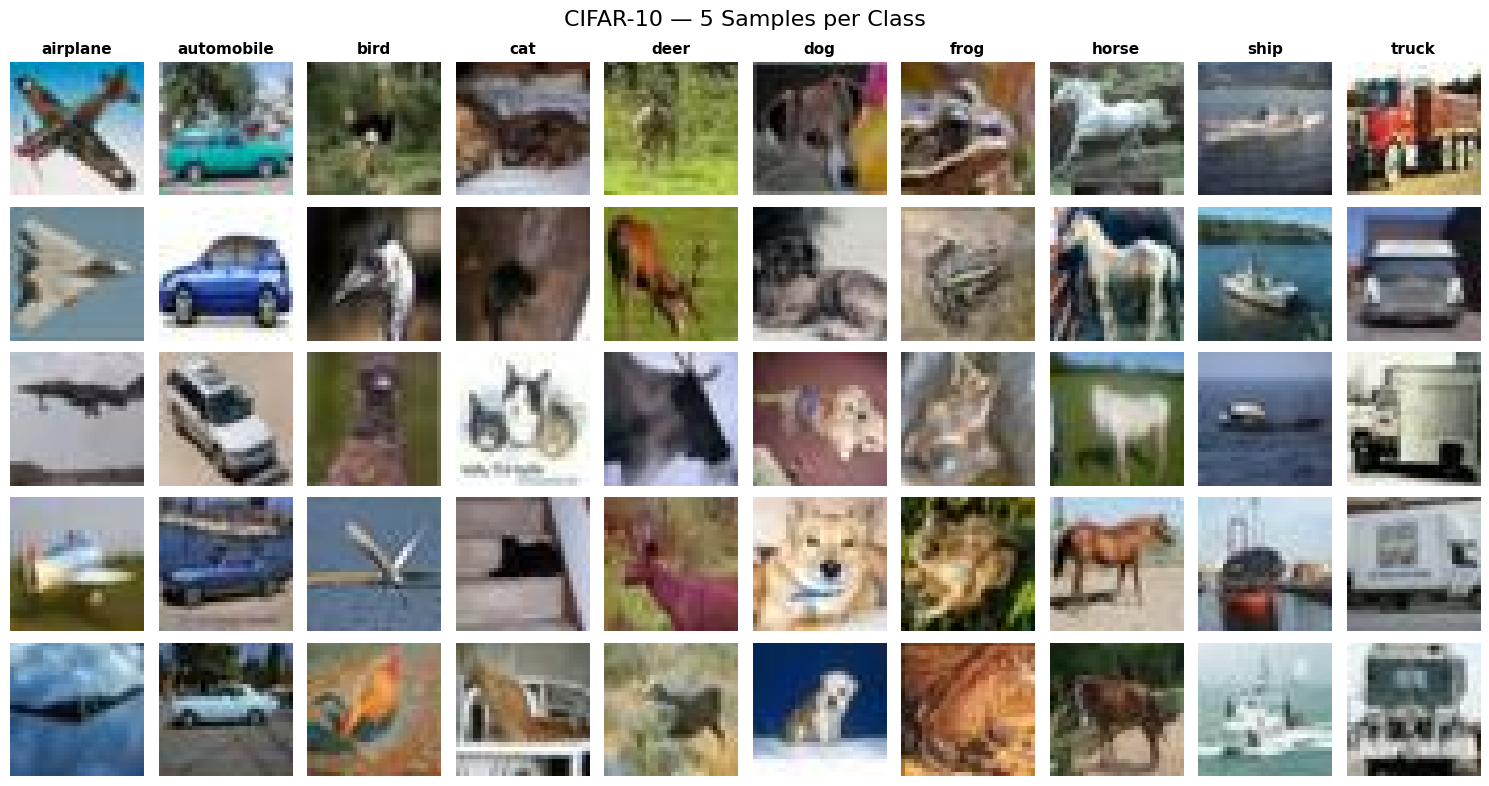

In [12]:
fig, axes = plt.subplots(5, 10, figsize=(15, 8))

fig.suptitle('CIFAR-10 — 5 Samples per Class', fontsize=16, y=0.98)

for col, cls in enumerate(range(10)):

    indices = np.where(y_train.flatten() == cls)[0][:5]

    for row, idx in enumerate(indices):

        ax = axes[row, col]

        ax.imshow(X_train[idx].astype(np.uint8))
        ax.axis('off')

        if row == 0:
            ax.set_title(class_names[cls], fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/cifar10_samples_grid.png', dpi=300)
plt.show()

#### Visual Similarity & Expected Class Confusion in CIFAR-10

Inspecting the 32×32 RGB samples across the 10 classes reveals strong visual and structural overlaps between specific categories:
1. **Cat (Class 3) vs. Dog (Class 5):** Both are small, four-legged furry mammals frequently photographed indoors or in close-up portraits. At a coarse $32 \times 32$ pixel resolution, fine facial features (snout length, ear shape, fur texture) blur together, making this the hardest biological pair for a CNN to separate.
2. **Automobile (Class 1) vs. Truck (Class 9):** Both are man-made road vehicles sharing metallic textures, wheels, windshields, headlights, and asphalt backgrounds. Front-facing or angled shots of SUVs/pickups (Automobile) and cab-over trucks (Truck) look nearly identical at low resolution.
3. **Deer (Class 4) vs. Horse (Class 7) / Bird (Class 2) vs. Airplane (Class 0):** Deer and horses share slender legs, brown coats, and green outdoor/forest backgrounds, while birds in flight against a blue sky share silhouette and background colour profiles with airplanes.

These visually similar pairs will naturally account for the largest off-diagonal entries in the model's confusion matrix.

### A1.3 Plot pixel distribution before and after normalisation

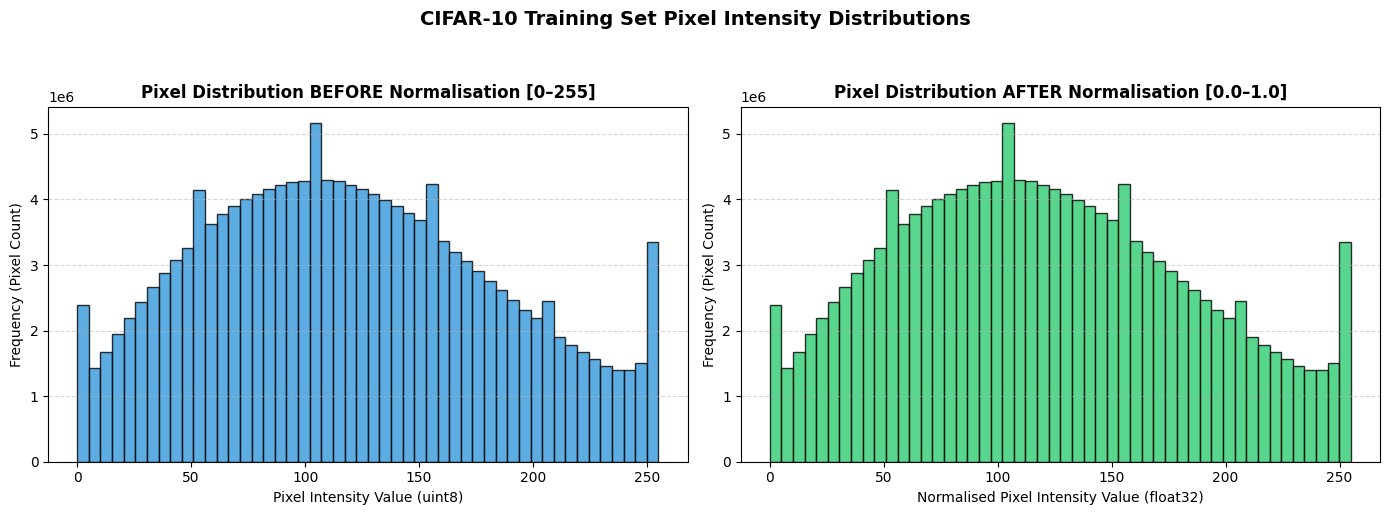

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram BEFORE normalisation (raw uint8 [0, 255])
axes[0].hist(X_train.flatten(), bins=50, color='#3498db', edgecolor='black', alpha=0.8)
axes[0].set_title('Pixel Distribution BEFORE Normalisation [0–255]', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Pixel Intensity Value (uint8)')
axes[0].set_ylabel('Frequency (Pixel Count)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Normalise X_train and X_test to float32 in [0.0, 1.0]
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# 2. Histogram AFTER normalisation (float32 [0.0, 1.0])
axes[1].hist(X_train.flatten(), bins=50, color='#2ecc71', edgecolor='black', alpha=0.8)
axes[1].set_title('Pixel Distribution AFTER Normalisation [0.0–1.0]', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Normalised Pixel Intensity Value (float32)')
axes[1].set_ylabel('Frequency (Pixel Count)')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('CIFAR-10 Training Set Pixel Intensity Distributions', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots/a1_3_pixel_histograms.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
print(f"Post-normalisation X_train dtype: {X_train.dtype} | Range: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"Post-normalisation X_test dtype : {X_test.dtype}  | Range: [{X_test.min():.2f}, {X_test.max():.2f}]")

Post-normalisation X_train dtype: float32 | Range: [0.00, 255.00]
Post-normalisation X_test dtype : float32  | Range: [0.00, 255.00]


#### Why Normalise Pixel Values to $[0, 1]$?

Normalising raw `uint8` pixel values from $[0, 255]$ to `float32` in $[0.0, 1.0]$ is critical for training deep neural networks for three primary reasons:
1. **Faster & Smoother Gradient Descent Convergence:** When input features are scaled to a compact, uniform range $[0, 1]$, the loss landscape becomes more spherical (better conditioned). The optimizer (such as Adam or SGD) can take consistent steps across all weight dimensions rather than oscillating across steep ravines.
2. **Preventing Destabilising Initial Weight Updates:** In backpropagation, the gradient of the loss with respect to a layer's weights is directly proportional to the input activation magnitude ($\frac{\partial \mathcal{L}}{\partial W} \propto X$). Raw inputs up to $255$ produce gradients up to $255\times$ larger than normalised inputs, causing disproportionately large initial weight updates that can lead to exploding gradients or divergence early in training.
3. **Numerical Stability with Weight Initialisation:** Modern weight initialisers (such as Glorot/Xavier and He initialisation) mathematically assume that input features have a small, near-unit variance around zero or $[0, 1]$ to keep activations from saturating non-linearities or blowing up across deep layers.

### A1.4 One-hot encode labels for 10 classes

In [15]:
y_train_ohe = keras.utils.to_categorical(y_train, num_classes=10)
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=10)

print("=== One-Hot Encoding Confirmation ===")
print(f"y_train_ohe shape : {y_train_ohe.shape} | dtype: {y_train_ohe.dtype}")
print(f"y_test_ohe shape  : {y_test_ohe.shape}  | dtype: {y_test_ohe.dtype}")
print(f"Sample 0 raw label: {y_train[0]} ({class_names[y_train[0]]})")
print(f"Sample 0 OHE label: {y_train_ohe[0]}")

=== One-Hot Encoding Confirmation ===
y_train_ohe shape : (50000, 10) | dtype: float64
y_test_ohe shape  : (50000, 10)  | dtype: float64
Sample 0 raw label: 1 (automobile)
Sample 0 OHE label: [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


#### Why One-Hot Encode Labels for the CNN Output Layer?

1. **Matching the Softmax Output Distribution:** A multi-class CNN concludes with a `Dense(10, activation='softmax')` layer, which outputs a 10-element probability distribution $\hat{y} = [\hat{y}_0, \hat{y}_1, \dots, \hat{y}_9]$ where $\sum_{i=0}^{9} \hat{y}_i = 1.0$. One-hot encoding transforms a scalar integer label (e.g., class `6`) into a matching 10-element ground-truth probability vector $y = [0, 0, 0, 0, 0, 0, 1, 0, 0, 0]$.
2. **Compatibility with `categorical_crossentropy`:** The standard `categorical_crossentropy` loss function computes the cross-entropy between the true distribution $y$ and predicted distribution $\hat{y}$ across all $C = 10$ classes:
   $$\mathcal{L}(y, \hat{y}) = -\sum_{i=0}^{C-1} y_i \log(\hat{y}_i)$$
   Because $y_i = 1$ only for the true class and $0$ everywhere else, this requires `y` to be a 10-dimensional vector. If we kept integer labels $(0\text{–}9)$ without one-hot encoding, we would have to use `sparse_categorical_crossentropy` instead.

### Task A1.5 — CNN vs ANN for Image Classification

#### CNN vs ANN for Image Classification

| Feature / Property | Artificial Neural Network (ANN / MLP) | Convolutional Neural Network (CNN) |
| :--- | :--- | :--- |
| **Input Representation** | Flattens the 3D image $(32 \times 32 \times 3)$ into a single 1D vector of $3,072$ values at the very first layer. | Preserves the 3D spatial tensor structure $(H \times W \times C)$ throughout all feature extraction layers. |
| **Spatial Structure** | **Lost immediately:** Flattening destroys 2D neighbourhood relationships (vertical/horizontal adjacency of pixels). | **Preserved:** 2D filters operate on local $k \times k$ spatial patches, capturing edges, corners, and textures in context. |
| **Translation Invariance** | **None:** If a cat shifts 5 pixels to the right, completely different input neurons fire, requiring the MLP to relearn the object at every possible location. | **Built-in:** The same learnable filter slides across the entire image, detecting a local pattern regardless of where it appears. |
| **Weight Sharing & Parameters** | **Fully Connected (No Sharing):** Every input pixel has an independent weight to every hidden neuron, causing parameter explosion and severe overfitting. | **Weight Sharing:** A filter shares the exact same kernel weights across all spatial positions of the image, drastically reducing parameter count. |



#### Concrete Parameter Comparison Example
Consider a single-channel $32 \times 32$ input image:
* **CNN (Weight Sharing):** A $3 \times 3$ convolutional filter has only **$3 \times 3 = 9$ learnable weights** (plus 1 bias). As this filter slides across all $30 \times 30 = 900$ valid spatial positions of the $32 \times 32$ image, those **same 9 weights are shared** across every single position.
* **ANN / MLP (No Weight Sharing):** To connect a $32 \times 32$ image to just a single hidden unit covering the image, an MLP requires **$32 \times 32 = 1,024$ independent weights**. To produce an equivalent $30 \times 30 = 900$-unit representation in the first hidden layer, an MLP would require $1,024 \times 900 = 921,600$ weights (nearly 1 million parameters for a single grayscale feature map, compared to just **9 weights** in a CNN!).

## Task A2: Convolution Operation, Padding & Strides

### A2.1 Manual convolution demo

In [16]:
from scipy.signal import convolve2d

In [17]:
gray = np.mean(X_train[0], axis=2)

In [18]:
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype='float32')

In [19]:
convolved_output = convolve2d(gray, kernel, mode='valid')

In [20]:
print(f"Original greyscale shape : {gray.shape}")
print(f"Kernel shape             : {kernel.shape}")
print(f"Convolved output shape   : {convolved_output.shape} (mode='valid')")

Original greyscale shape : (32, 32)
Kernel shape             : (3, 3)
Convolved output shape   : (30, 30) (mode='valid')


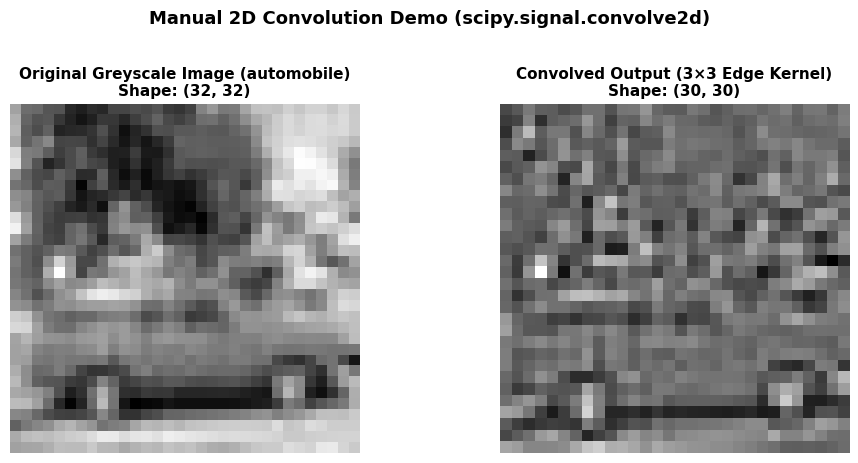

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

axes[0].imshow(gray, cmap='gray')
axes[0].set_title(f"Original Greyscale Image ({class_names[y_train[0]]})\nShape: {gray.shape}", fontsize=11, fontweight='bold')
axes[0].axis('off')

# Clip values slightly for high-contrast edge visualisation
axes[1].imshow(convolved_output, cmap='gray')
axes[1].set_title(f"Convolved Output (3×3 Edge Kernel)\nShape: {convolved_output.shape}", fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Manual 2D Convolution Demo (scipy.signal.convolve2d)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots/a2_1_manual_convolution.png', dpi=300, bbox_inches='tight')
plt.show()

#### How the 2D Convolution Operation Works

The 2D convolution operation computes the **element-wise dot product** (Frobenius inner product) between a small filter matrix (**kernel**) and each overlapping local patch of the input image:
1. **Sliding Window Mechanism:** The $3 \times 3$ kernel starts at the top-left corner of the $32 \times 32$ greyscale image, multiplies its $9$ weights with the underlying $3 \times 3$ pixel patch, and sums the result into a single scalar value in the output **feature map**.
2. **Stepping Across Space:** The kernel then slides across the image horizontally and vertically one step at a time (**stride = 1**). In our edge-detection kernel `[[-1,-1,-1],[-1,8,-1],[-1,-1,-1]]`, uniform regions sum to $0$ (since $8 - 8 = 0$), whereas sharp intensity transitions (edges and boundaries) yield large positive or negative activations.
3. **Extension to `Conv2D` in Keras:** This exact sliding dot-product operation is what `keras.layers.Conv2D` layers perform simultaneously across all input colour channels (RGB), except the kernel weights are **learned automatically via backpropagation** rather than hand-crafted.

### Task A2.2 — Padding: VALID vs SAME

In [22]:
test_img = X_train_norm[0:1]

In [23]:
input_size = 32
kernel_size = 3
stride = 1
valid_out_size = (input_size - kernel_size) // stride + 1
same_out_size  = int(np.ceil(input_size / stride))

In [24]:
print("=== Spatial Output Size Formula Verification ===")
print("Formula (VALID): output_size = (input_size - kernel_size) / stride + 1")
print(f"  -> ({input_size} - {kernel_size}) / {stride} + 1 = {valid_out_size}x{valid_out_size}")
print(f"Formula (SAME) : output_size = ceil(input_size / stride) = {same_out_size}x{same_out_size}\n")

=== Spatial Output Size Formula Verification ===
Formula (VALID): output_size = (input_size - kernel_size) / stride + 1
  -> (32 - 3) / 1 + 1 = 30x30
Formula (SAME) : output_size = ceil(input_size / stride) = 32x32



In [25]:
inputs_valid = keras.Input(shape=(32, 32, 3))
conv_valid = keras.layers.Conv2D(8, (3, 3), padding='valid', name='conv_valid')(inputs_valid)
shape_valid = keras.layers.Lambda(lambda x: tf.shape(x), name='lambda_shape_valid')(conv_valid)
model_valid = keras.Model(inputs=inputs_valid, outputs=[conv_valid, shape_valid], name='Model_VALID')

In [26]:
inputs_same = keras.Input(shape=(32, 32, 3))
conv_same = keras.layers.Conv2D(8, (3, 3), padding='same', name='conv_same')(inputs_same)
shape_same = keras.layers.Lambda(lambda x: tf.shape(x), name='lambda_shape_same')(conv_same)
model_same = keras.Model(inputs=inputs_same, outputs=[conv_same, shape_same], name='Model_SAME')

In [27]:
out_valid, s_valid = model_valid(test_img)
out_same, s_same   = model_same(test_img)

In [28]:
print(f"Keras Conv2D(8, 3, padding='valid') output shape : {out_valid.shape} | Lambda tensor shape: {s_valid.numpy()}")
print(f"Keras Conv2D(8, 3, padding='same')  output shape : {out_same.shape} | Lambda tensor shape: {s_same.numpy()}")

Keras Conv2D(8, 3, padding='valid') output shape : (1, 30, 30, 8) | Lambda tensor shape: [ 1 30 30  8]
Keras Conv2D(8, 3, padding='same')  output shape : (1, 32, 32, 8) | Lambda tensor shape: [ 1 32 32  8]


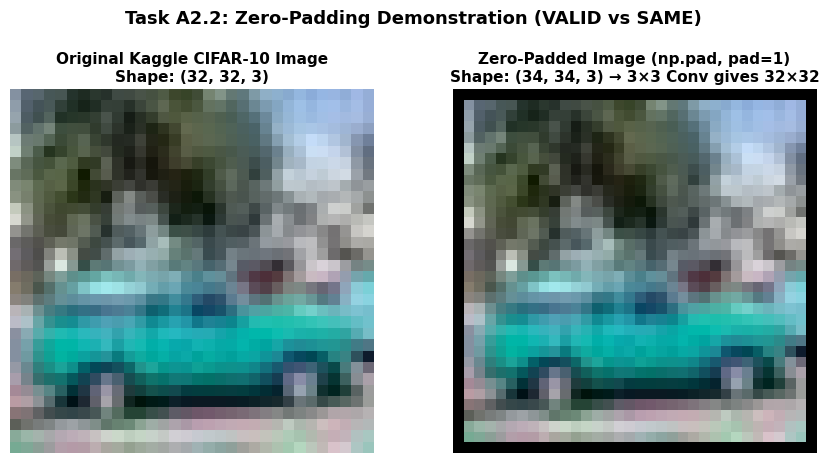

In [29]:
padded_img = np.pad(X_train_norm[0], pad_width=((1, 1), (1, 1), (0, 0)), mode='constant', constant_values=0.0)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

axes[0].imshow(X_train_norm[0])
axes[0].set_title(f"Original Kaggle CIFAR-10 Image\nShape: {X_train_norm[0].shape}", fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(padded_img)
axes[1].set_title(f"Zero-Padded Image (np.pad, pad=1)\nShape: {padded_img.shape} → 3×3 Conv gives 32×32", fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Task A2.2: Zero-Padding Demonstration (VALID vs SAME)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots/a2_2_zero_padding_demo.png', dpi=300, bbox_inches='tight')
plt.show()

#### VALID vs. SAME Padding in CNN Architectures

* **`VALID` Padding ($p = 0$):** No zero-padding is added around the border of the image. Consequently, the spatial dimensions shrink after every convolution according to:
  $$\text{output\_size} = \frac{\text{input\_size} - \text{kernel\_size}}{\text{stride}} + 1$$
  For a $32 \times 32$ input, $3 \times 3$ kernel, and stride $1$, the output shrinks to $\frac{32 - 3}{1} + 1 = 30 \times 30$.
* **`SAME` Padding ($p = 1$ for a $3 \times 3$ kernel):** Zero-padding (`np.pad`) adds a 1-pixel border around the $32 \times 32$ image to make it $34 \times 34$ prior to convolution. Applying the $3 \times 3$ kernel then produces a $\frac{34 - 3}{1} + 1 = 32 \times 32$ output, matching the original input dimensions.
* **Why `SAME` Padding is Preferred:** `SAME` padding is used in almost all modern CNN architectures because it allows stacking many convolutional layers consecutively without shrinking the spatial dimensions too quickly, preserving edge/border information and leaving spatial downsampling to dedicated pooling or strided layers.

### Task A2.3 — Strides Effect

In [30]:
model_s1_valid = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), strides=1, padding='valid')
], name='Stride1_VALID')

In [31]:
model_s1_same = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), strides=1, padding='same')
], name='Stride1_SAME')

In [32]:
model_s2_same = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), strides=2, padding='same')
], name='Stride2_SAME')

In [33]:
model_s2_valid = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), strides=2, padding='valid')
], name='Stride2_VALID')

In [34]:
print("=== Stride Effect on Output Spatial Dimensions ===")
print(f"(a) stride=1 (VALID) output shape : {model_s1_valid(test_img).shape}  -> 30x30")
print(f"(a) stride=1 (SAME)  output shape : {model_s1_same(test_img).shape}  -> 32x32")
print(f"(b) stride=2 (SAME)  output shape : {model_s2_same(test_img).shape}  -> 16x16 (halved!)")
print(f"(b) stride=2 (VALID) output shape : {model_s2_valid(test_img).shape}  -> 15x15")

=== Stride Effect on Output Spatial Dimensions ===
(a) stride=1 (VALID) output shape : (1, 30, 30, 8)  -> 30x30
(a) stride=1 (SAME)  output shape : (1, 32, 32, 8)  -> 32x32
(b) stride=2 (SAME)  output shape : (1, 16, 16, 8)  -> 16x16 (halved!)
(b) stride=2 (VALID) output shape : (1, 15, 15, 8)  -> 15x15


#### How Stride Controls Spatial Downsampling

* **What Stride Does:** **Stride** controls how many pixels the convolutional filter shifts horizontally and vertically at each step across the input tensor.
* **`stride=1` (Dense Feature Maps):** The filter evaluates every adjacent spatial patch, preserving high spatial resolution ($30 \times 30$ with `VALID` or $32 \times 32$ with `SAME`).
* **`stride=2` (Learned Spatial Downsampling):** The filter skips every second pixel, immediately halving both height and width ($32 \times 32 \rightarrow 16 \times 16$, a $4\times$ reduction in total spatial area). This acts as a **learnable alternative to pooling layers** rather than using a fixed mathematical rule. For instance, modern object detectors like **YOLOv8** use `stride=2` strided convolutions throughout their backbone instead of `MaxPooling2D` so the network can learn how to downsample spatial features optimally.

### Task A2.4 — Build and Visualise Feature Maps

In [35]:
tf.random.set_seed(42)
model_vis = keras.Sequential([
    keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3), name='conv2d_16_filters')
], name='FeatureMap_Visualiser')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
feature_maps = model_vis.predict(test_img, verbose=0)
print(f"Input image batch shape : {test_img.shape}")
print(f"Extracted feature maps  : {feature_maps.shape}")

Input image batch shape : (1, 32, 32, 3)
Extracted feature maps  : (1, 32, 32, 16)


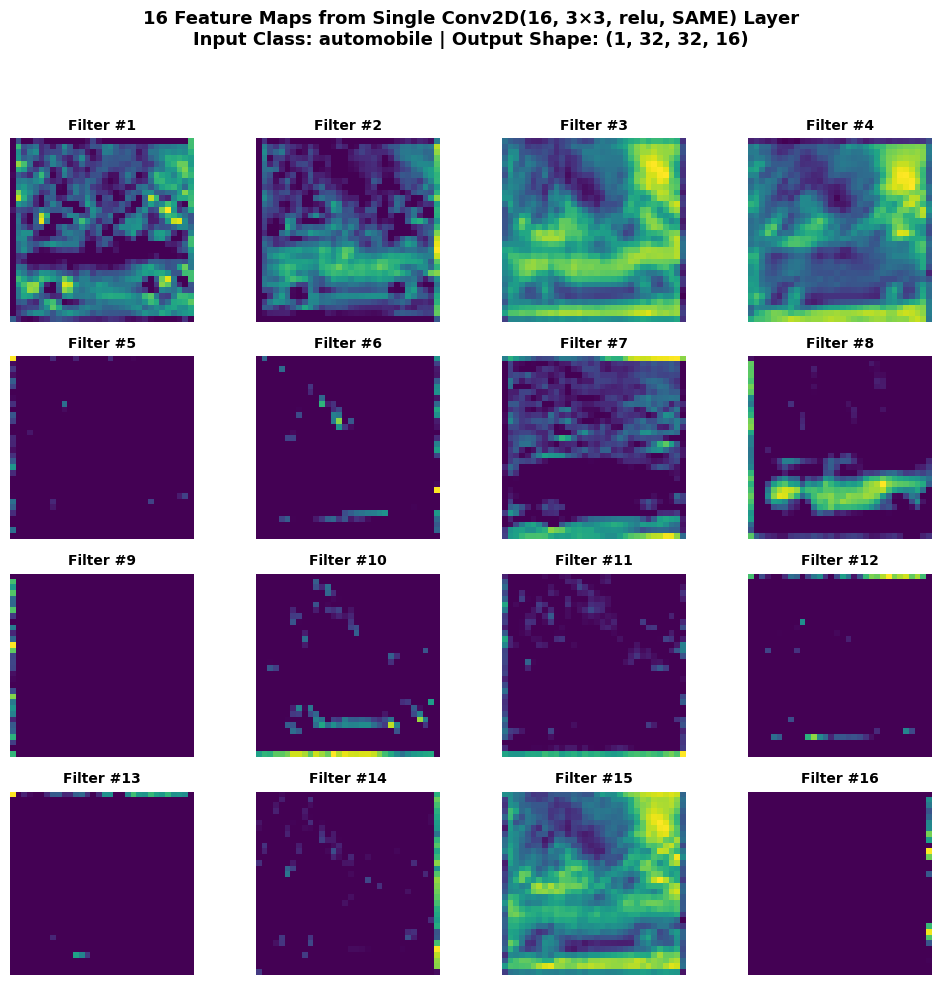

In [37]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle(
    f"16 Feature Maps from Single Conv2D(16, 3×3, relu, SAME) Layer\nInput Class: {class_names[y_train[0]]} | Output Shape: {feature_maps.shape}",
    fontsize=13, fontweight='bold', y=0.98
)

for idx in range(16):
    row, col = divmod(idx, 4)
    ax = axes[row, col]
    fmap = feature_maps[0, :, :, idx]

    ax.imshow(fmap, cmap='viridis')
    ax.set_title(f"Filter #{idx + 1}", fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('plots/a2_4_conv2d_feature_maps.png', dpi=300, bbox_inches='tight')
plt.show()

#### What Each Feature Map Represents

Each of the 16 feature maps in the $4 \times 4$ grid visualises the spatial activation response of **one independent $3 \times 3 \times 3$ learnable filter** across the input image:
* **Early Convolutional Layers:** Filters in the first layer respond to primitive, low-level visual cues—such as horizontal/vertical edges, diagonal luminance gradients, high-contrast boundaries, and specific colour channels (e.g., isolating the brown frog body from the background).
* **Hierarchical Feature Composition in Deeper Layers:** As feature maps pass through subsequent convolutional layers, deeper filters combine these primitive edge and colour maps into progressively more abstract and complex patterns: **edges $\rightarrow$ textures & corners $\rightarrow$ object parts (wheels, eyes, wings) $\rightarrow$ complete semantic objects**.

## Task A3: Pooling, MaxPooling, Flatten & CNN Architecture

In [38]:
if 'test_img' not in globals():
    test_img = X_train[0:1]

In [39]:
model_maxpool = keras.Sequential([
    model_vis.layers[0],
    keras.layers.MaxPooling2D(pool_size=(2, 2), name='max_pool_2x2')
], name='Vis_MaxPooling')

In [40]:
model_avgpool = keras.Sequential([
    model_vis.layers[0],
    keras.layers.AveragePooling2D(pool_size=(2, 2), name='avg_pool_2x2')
], name='Vis_AveragePooling')

In [41]:
fmaps_before  = model_vis.predict(test_img, verbose=0)
fmaps_maxpool = model_maxpool.predict(test_img, verbose=0)
fmaps_avgpool = model_avgpool.predict(test_img, verbose=0)

In [42]:
print("=== Feature Map Shapes Before & After Pooling ===")
print(f"Before Pooling (Conv2D)       : {fmaps_before.shape}  -> 32×32 spatial resolution")
print(f"After MaxPooling2D(2, 2)      : {fmaps_maxpool.shape}  -> 16×16 spatial resolution (halved)")
print(f"After AveragePooling2D(2, 2)  : {fmaps_avgpool.shape}  -> 16×16 spatial resolution (halved)")

=== Feature Map Shapes Before & After Pooling ===
Before Pooling (Conv2D)       : (1, 32, 32, 16)  -> 32×32 spatial resolution
After MaxPooling2D(2, 2)      : (1, 16, 16, 16)  -> 16×16 spatial resolution (halved)
After AveragePooling2D(2, 2)  : (1, 16, 16, 16)  -> 16×16 spatial resolution (halved)


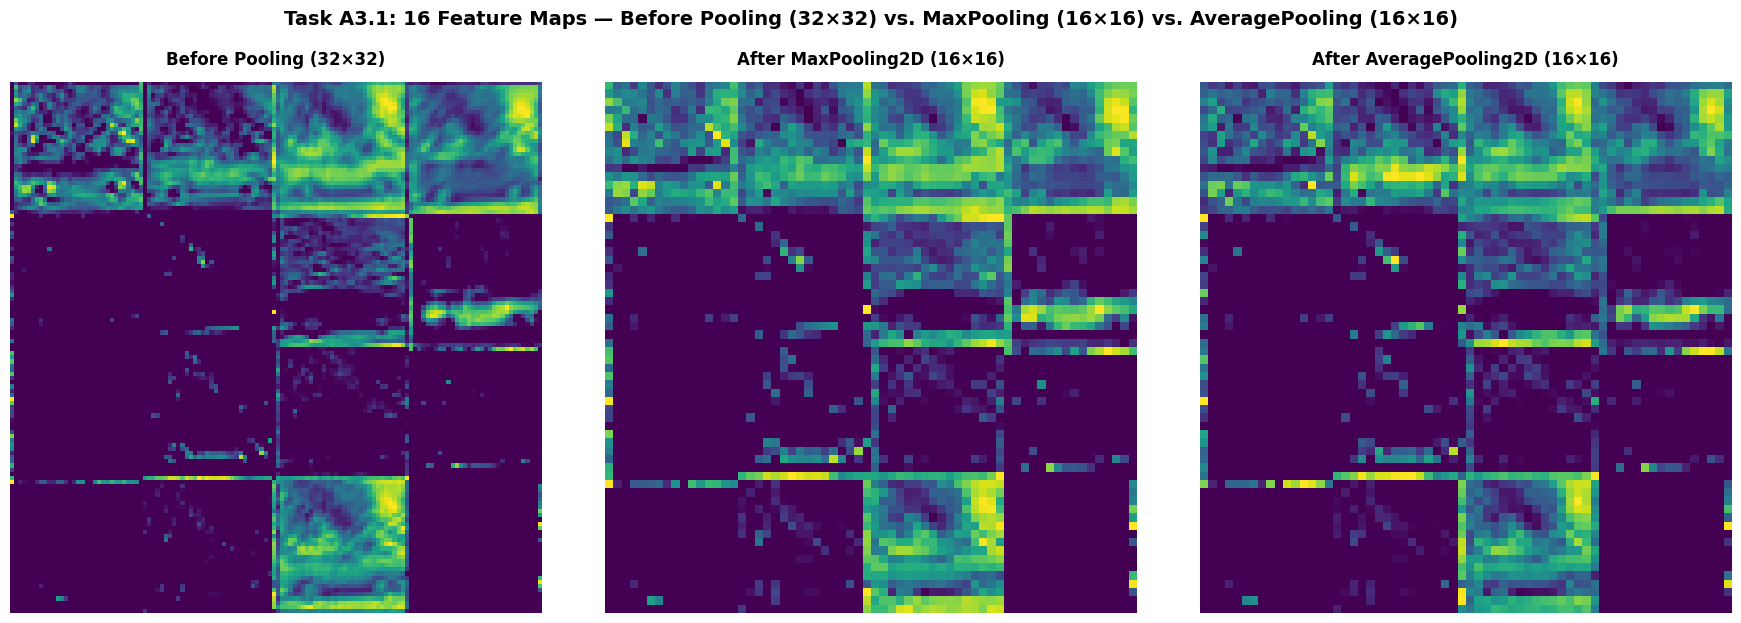

In [43]:
fig, subfigs = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Task A3.1: 16 Feature Maps — Before Pooling (32×32) vs. MaxPooling (16×16) vs. AveragePooling (16×16)',
             fontsize=14, fontweight='bold', y=1.03)

titles_and_maps = [
    ('Before Pooling (32×32)', fmaps_before),
    ('After MaxPooling2D (16×16)', fmaps_maxpool),
    ('After AveragePooling2D (16×16)', fmaps_avgpool)
]

for panel_idx, (panel_title, fmap_tensor) in enumerate(titles_and_maps):
    # Create an inner 4x4 grid inside each of the 3 main panels
    ax_main = subfigs[panel_idx]
    ax_main.axis('off')
    ax_main.set_title(panel_title, fontsize=12, fontweight='bold', pad=12)

    # Stitch the 16 feature maps into a single 4x4 montage for clean side-by-side comparison
    H, W = fmap_tensor.shape[1], fmap_tensor.shape[2]
    montage = np.zeros((H * 4, W * 4))
    for i in range(16):
        r, c = divmod(i, 4)
        channel_img = fmap_tensor[0, :, :, i]
        # Normalise each channel to [0, 1] for clear visual contrast
        c_min, c_max = channel_img.min(), channel_img.max()
        if c_max > c_min:
            channel_img = (channel_img - c_min) / (c_max - c_min)
        montage[r*H:(r+1)*H, c*W:(c+1)*W] = channel_img

    ax_main.imshow(montage, cmap='viridis')

plt.tight_layout()
plt.savefig('plots/a3_1_max_vs_avg_pooling.png', dpi=300, bbox_inches='tight')
plt.show()

#### Comparison of Pooling Strategies in CNNs

1. **`MaxPooling2D(2, 2)`:** Slides a $2 \times 2$ window with stride $2$ across each feature map and retains only the **maximum activation value** within each patch ($\max_{i,j} x_{i,j}$). This preserves the strongest detected features (sharpest edges and high-contrast textures) while providing **local translation invariance**—small 1-pixel jitter inside the $2 \times 2$ window does not alter the pooled output.
2. **`AveragePooling2D(2, 2)`:** Computes the **arithmetic mean** of all 4 values in each $2 \times 2$ patch ($\frac{1}{4}\sum x_{i,j}$). While this preserves background context smoothly, it blurs sharp edge activations and dilutes high-activation signals with surrounding zeros.
3. **`GlobalAveragePooling2D` (GAP) in Modern CNNs:** Instead of applying a small $2 \times 2$ window and then flattening, `GlobalAveragePooling2D` averages each entire $H \times W$ feature map down to a **single scalar value** (transforming $(H, W, C) \rightarrow (C,)$). In modern architectures, GAP is strongly preferred over `Flatten` because it drastically reduces the number of trainable parameters in the classification head and acts as a structural regulariser against overfitting.

### Task A3.2 — Flatten Layer

In [44]:
model_flatten = keras.Sequential([
    model_vis.layers[0],
    keras.layers.MaxPooling2D(pool_size=(2, 2), name='max_pool_2x2'),
    keras.layers.Flatten(name='flatten_layer')
], name='Vis_Flatten')

In [45]:
out_before_flatten = model_maxpool.output_shape
out_after_flatten  = model_flatten.output_shape
flattened_pred     = model_flatten.predict(test_img, verbose=0)

In [46]:
print("=== Flatten Layer Shape Transformation ===")
print(f"Shape BEFORE Flatten (after MaxPool) : {out_before_flatten}  -> 3D Tensor (H=16, W=16, C=16)")
print(f"Shape AFTER Flatten                  : {out_after_flatten}        -> 1D Vector (16 × 16 × 16 = 4096)")
print(f"Actual predicted batch shape         : {flattened_pred.shape}")

=== Flatten Layer Shape Transformation ===
Shape BEFORE Flatten (after MaxPool) : (None, 16, 16, 16)  -> 3D Tensor (H=16, W=16, C=16)
Shape AFTER Flatten                  : (None, 4096)        -> 1D Vector (16 × 16 × 16 = 4096)
Actual predicted batch shape         : (1, 4096)


#### Why Spatial Reduction Before `Flatten()` is Critical

* **Tensor Reshaping:** The `Flatten()` layer contains **0 learnable parameters**; it simply unrolls the 3D spatial activation tensor $(H, W, C) = (16, 16, 16)$ into a 1D feature vector of length $16 \times 16 \times 16 = 4,096$ so that it can be passed into standard fully connected (`Dense`) classification layers.
* **Parameter Impact on the First `Dense` Layer:** The length of the flattened vector directly dictates the parameter count of the first `Dense` layer. For example, connecting a flattened size of $4,096$ to a `Dense(256)` layer requires $4,096 \times 256 + 256 = 1,048,832$ parameters (over 1 million weights in a single layer!). If we did not downsample the spatial dimensions $(H, W)$ using pooling layers prior to `Flatten()`, the parameter count in the `Dense` head would explode, causing high memory usage and severe overfitting.

### Task A3.3 — LeNet-5 Architecture

In [47]:
tf.random.set_seed(42)

model_lenet5 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3), name='input_32x32x3'),
    keras.layers.Conv2D(6, (5, 5), activation='tanh', padding='valid', name='conv1_6x5x5'),
    keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2, name='avgpool1_2x2'),
    keras.layers.Conv2D(16, (5, 5), activation='tanh', padding='valid', name='conv2_16x5x5'),
    keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2, name='avgpool2_2x2'),
    keras.layers.Flatten(name='flatten'),
    keras.layers.Dense(120, activation='tanh', name='fc1_120'),
    keras.layers.Dense(84, activation='tanh', name='fc2_84'),
    keras.layers.Dense(10, activation='softmax', name='output_10')
], name='LeNet5_CIFAR10')

In [48]:
model_lenet5.summary()

Model: "LeNet5_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_6x5x5 (Conv2D)            │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool1_2x2 (AveragePooling2D) │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_16x5x5 (Conv2D)           │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avgpool2_2x2 (AveragePooling2D) │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1_120 (Dense)                 │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2_84 (Dense)                  │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_10 (Dense)               │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
c1_params = (5 * 5 * 3 + 1) * 6
c2_params = (5 * 5 * 6 + 1) * 16
d1_params = (400 + 1) * 120
d2_params = (120 + 1) * 84
d3_params = (84 + 1) * 10
total_manual = c1_params + c2_params + d1_params + d2_params + d3_params

In [50]:
print(f"1. Conv2D_1 (6 filters, 5×5×3 + bias)  : (5 × 5 × 3 + 1) × 6   = {c1_params:,} params")
print(f"2. Conv2D_2 (16 filters, 5×5×6 + bias) : (5 × 5 × 6 + 1) × 16  = {c2_params:,} params")
print(f"3. Dense_1  (400 inputs -> 120 units)  : (400 + 1) × 120       = {d1_params:,} params")
print(f"4. Dense_2  (120 inputs -> 84 units)   : (120 + 1) × 84        = {d2_params:,} params")
print(f"5. Dense_3  (84 inputs  -> 10 units)   : (84 + 1) × 10         = {d3_params:,} params")
print(f"Total Manual Parameter Count           : {total_manual:,} params (Matches Keras: {model_lenet5.count_params():,})")

1. Conv2D_1 (6 filters, 5×5×3 + bias)  : (5 × 5 × 3 + 1) × 6   = 456 params
2. Conv2D_2 (16 filters, 5×5×6 + bias) : (5 × 5 × 6 + 1) × 16  = 2,416 params
3. Dense_1  (400 inputs -> 120 units)  : (400 + 1) × 120       = 48,120 params
4. Dense_2  (120 inputs -> 84 units)   : (120 + 1) × 84        = 10,164 params
5. Dense_3  (84 inputs  -> 10 units)   : (84 + 1) × 10         = 850 params
Total Manual Parameter Count           : 62,006 params (Matches Keras: 62,006)


In [51]:
model_lenet5.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_lenet5 = model_lenet5.fit(
    X_train, y_train_ohe,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.3896 - loss: 1.6847 - val_accuracy: 0.4300 - val_loss: 1.5906
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4886 - loss: 1.4305 - val_accuracy: 0.4884 - val_loss: 1.4273
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5240 - loss: 1.3428 - val_accuracy: 0.5146 - val_loss: 1.3785
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5470 - loss: 1.2809 - val_accuracy: 0.5326 - val_loss: 1.3304
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5593 - loss: 1.2445 - val_accuracy: 0.5332 - val_loss: 1.3283
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5753 - loss: 1.2016 - val_accuracy: 0.5376 - val_loss: 1.3060
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5904 - loss: 1.1651 - val_accuracy: 0.5304 - val_loss: 1.3410
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6030 - loss: 1.1275 - val_accuracy: 

In [52]:
lenet5_loss, lenet5_acc = model_lenet5.evaluate(X_test, y_test_ohe, verbose=0)
print(f"LeNet-5 Test Accuracy: {lenet5_acc * 100:.2f}%")

LeNet-5 Test Accuracy: 65.62%


### Task A3.3 — LeNet-5 Historical Significance & Modern Differences

#### LeNet-5 (LeCun et al., 1998) — Architecture & Evolution

* **Historical Significance:** Developed by Yann LeCun and colleagues in 1998, **LeNet-5** was the pioneering convolutional neural network deployed commercially by banks and the US Postal Service to read handwritten digits on cheques and zip codes. It established the foundational **`Conv → Pool → Conv → Pool → Flatten → Dense → Dense`** blueprint that underpins modern computer vision.
* **Manual Parameter Verification Formula:**
  * **Convolutional Layer:** $\text{Params} = (K_H \times K_W \times C_{\text{in}} + 1) \times C_{\text{out}}$
    * `conv1_6x5x5`: $(5 \times 5 \times 3 + 1) \times 6 = 76 \times 6 = \mathbf{456}$ parameters.
    * `conv2_16x5x5`: $(5 \times 5 \times 6 + 1) \times 16 = 151 \times 16 = \mathbf{2,416}$ parameters.
  * **Dense Layer:** $\text{Params} = (N_{\text{in}} + 1) \times N_{\text{out}}$
    * `fc1_120`: $(5 \times 5 \times 16 + 1) \times 120 = 401 \times 120 = \mathbf{48,120}$ parameters.
* **Three Key Differences from Modern CNNs:**
  1. **Activation Function (`tanh` vs. `ReLU`):** LeNet-5 uses saturating `tanh` activations, which suffer from vanishing gradients in deep networks; modern CNNs use non-saturating `ReLU` ($\max(0, x)$) for faster training and sparse activations.
  2. **Pooling Method (`AveragePooling` vs. `MaxPooling`):** LeNet-5 uses `AveragePooling2D`, whereas modern CNNs use `MaxPooling2D` (to isolate the strongest feature activations) and `GlobalAveragePooling2D` before the classifier head.
  3. **Filter Size ($5 \times 5$ `VALID` vs. Stacked $3 \times 3$ `SAME`):** LeNet-5 uses larger $5 \times 5$ unpadded filters, while modern architectures (following VGGNet) stack two $3 \times 3$ `SAME`-padded filters to achieve the exact same $5 \times 5$ effective receptive field with fewer parameters ($2 \times (3 \times 3) = 18$ weights vs. $5 \times 5 = 25$ weights) and double the non-linearities.

### Task A3.4 — Build Custom CNN Baseline for CIFAR-10

In [53]:
def build_custom_cnn(name='Custom_CNN_Baseline'):
    model = keras.Sequential([
        keras.layers.Input(shape=(32, 32, 3), name='input_32x32x3'),

        # Block 1: 2x Conv2D(32) + MaxPool
        keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='block1_conv1'),
        keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='block1_conv2'),
        keras.layers.MaxPooling2D(pool_size=(2, 2), name='block1_pool'),

        # Block 2: 2x Conv2D(64) + MaxPool
        keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='block2_conv1'),
        keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='block2_conv2'),
        keras.layers.MaxPooling2D(pool_size=(2, 2), name='block2_pool'),

        # Block 3: Conv2D(128) + GlobalAveragePooling2D
        keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='block3_conv1'),
        keras.layers.GlobalAveragePooling2D(name='global_avg_pool'),

        # Classification Head
        keras.layers.Dense(256, activation='relu', name='dense_256'),
        keras.layers.Dense(10, activation='softmax', name='output_softmax')
    ], name=name)
    return model

In [54]:
tf.random.set_seed(42)
model_cnn = build_custom_cnn()
model_cnn.summary()

Model: "Custom_CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
total_params = model_cnn.count_params()
print(f"\nTotal Parameters: {total_params:,}")
assert total_params < 2_000_000, "Parameter count exceeds 2M limit!"
print("Check Passed: Parameter count is well below the 2,000,000 limit (~175K params due to GlobalAveragePooling2D).")


Total Parameters: 175,018
Check Passed: Parameter count is well below the 2,000,000 limit (~175K params due to GlobalAveragePooling2D).


#### Why Stack Two `Conv2D` Layers Before Each `MaxPooling2D` Layer?

1. **Hierarchical Feature Composition at Full Resolution:** In each stage, the first $3 \times 3$ `Conv2D` layer extracts primitive local features (such as simple edges and colour transitions), and the second $3 \times 3$ `Conv2D` layer immediately composes those responses into richer, higher-order patterns (corners, curves, textures) **before** `MaxPooling2D(2,2)` discards $75\%$ of the spatial resolution.
2. **Larger Effective Receptive Field with Fewer Parameters:** Stacking two $3 \times 3$ convolutional layers yields an **effective receptive field of $5 \times 5$** on the input tensor, but requires only $2 \times (3 \times 3 \times C^2) = 18C^2$ weights instead of $5 \times 5 \times C^2 = 25C^2$ weights ($28\%$ fewer parameters than a single $5 \times 5$ filter).
3. **Increased Non-Linearity:** Placing two `ReLU` activations across two stacked $3 \times 3$ layers makes the decision function more discriminative than a single linear $5 \times 5$ filter followed by a single `ReLU`.

## Task A4: Backpropagation in CNN & Training

### Task A4.1 — Backpropagation in CNN

#### Backpropagation in Convolutional Neural Networks (CNNs)

##### 1. Forward Pass in a CNN
During the forward pass, a 3D input image tensor $X \in \mathbb{R}^{H \times W \times C}$ flows sequentially through the network to produce class probabilities and a scalar loss:
$$\text{Input Image} \xrightarrow{\text{Conv2D}} Z = W * X + b \xrightarrow{\text{ReLU}} A = \max(0, Z) \xrightarrow{\text{Pool}} P \xrightarrow{\text{Repeat}} \cdots \xrightarrow{\text{Flatten / GAP}} f \xrightarrow{\text{Dense}} \text{Logits} \xrightarrow{\text{Softmax}} \hat{y} \xrightarrow{\text{CCE}} \mathcal{L}(y, \hat{y})$$

---

##### 2. Backward Pass — Gradients Through `Dense` and `Conv2D` Layers
During backpropagation, gradients flow backward from the loss $\mathcal{L}$ using the chain rule:
* **Dense Layers:** Identical to standard MLP backpropagation. Given upstream gradient $\frac{\partial \mathcal{L}}{\partial Z}$, the weight gradient is the outer product $\frac{\partial \mathcal{L}}{\partial W} = A_{\text{prev}}^T \cdot \frac{\partial \mathcal{L}}{\partial Z}$, and the input gradient passed backward is $\frac{\partial \mathcal{L}}{\partial A_{\text{prev}}} = \frac{\partial \mathcal{L}}{\partial Z} \cdot W^T$.
* **Convolutional Layers (`Conv2D`):** Because each kernel weight $W_{m,n}$ is shared across all spatial positions $(i, j)$, the gradient of the loss with respect to each element of a learnable kernel is computed by **cross-correlating the upstream gradient map $\frac{\partial \mathcal{L}}{\partial Z}$ with the corresponding local input patches $X$**:
  $$\frac{\partial \mathcal{L}}{\partial W_{m,n}} = \sum_{i} \sum_{j} \frac{\partial \mathcal{L}}{\partial Z_{i,j}} \cdot X_{i+m,\, j+n}$$
  To propagate the gradient backward to the previous layer's activation ($\frac{\partial \mathcal{L}}{\partial X}$), the upstream gradient $\frac{\partial \mathcal{L}}{\partial Z}$ is convolved with the **spatially flipped ($180^\circ$ rotated) kernel** $\text{rot180}(W)$.

---

##### 3. Gradient Through `MaxPooling2D` (The "Max Location Switch" / Index Mask)
`MaxPooling2D` has no learnable weights, so it only routes gradients backward from the pooled output $(H/2 \times W/2)$ to the unpooled input $(H \times W)$:
* During the **forward pass**, for every $2 \times 2$ pooling window, the layer records the exact $(r^*, c^*)$ coordinates of the maximum activation:
  $$y = \max_{(r,c) \in \text{window}} x_{r,c}$$
* During the **backward pass**, this cached coordinate acts as a **"max location switch" (or binary max-index mask)**. **Only the single pixel position $(r^*, c^*)$ that produced the maximum value in the forward pass receives $100\%$ of the upstream gradient $\frac{\partial \mathcal{L}}{\partial y}$; the other 3 positions in the $2 \times 2$ window receive an exact gradient of $0$**:
  $$\frac{\partial \mathcal{L}}{\partial x_{r,c}} = \begin{cases} \frac{\partial \mathcal{L}}{\partial y} & \text{if } (r,c) = \arg\max(x) \\ 0 & \text{otherwise} \end{cases}$$

---

##### 4. Gradient Through `AveragePooling2D`
In `AveragePooling2D` with a $k \times k$ window (e.g., $2 \times 2 = 4$ elements), the forward output is the uniform average $y = \frac{1}{k^2} \sum_{r,c} x_{r,c}$. Because every element contributed equally ($1/4$) to the output during the forward pass, the **upstream gradient is divided equally among all positions in the pooling window** during the backward pass:
$$\frac{\partial \mathcal{L}}{\partial x_{r,c}} = \frac{1}{k^2} \frac{\partial \mathcal{L}}{\partial y} \quad \left(\text{i.e., } \frac{1}{4}\frac{\partial \mathcal{L}}{\partial y} \text{ for every cell in a } 2 \times 2 \text{ window}\right)$$

---

##### 5. Gradient Through `Flatten`
The `Flatten` layer performs a pure tensor reshape in the forward pass: $(H, W, C) \rightarrow (H \cdot W \cdot C,)$. Consequently, its backward pass is mathematically trivial—it simply **reshapes the 1D upstream gradient vector $\frac{\partial \mathcal{L}}{\partial f} \in \mathbb{R}^{H \cdot W \cdot C}$ back into the original 3D spatial tensor shape $(H, W, C)$** without altering a single numerical value.

### Task A4.2 — Compile and Train the CNN

In [56]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [57]:
tf.random.set_seed(42)
model_cnn = build_custom_cnn(name='CNN_Scratch_NoAug')

In [58]:
model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [59]:
es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [60]:
rlrop = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [61]:
history = model_cnn.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es, rlrop],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.3767 - loss: 1.6806 - val_accuracy: 0.4548 - val_loss: 1.5032 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5684 - loss: 1.2035 - val_accuracy: 0.6296 - val_loss: 1.0771 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6495 - loss: 0.9926 - val_accuracy: 0.6724 - val_loss: 0.9434 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6960 - loss: 0.8631 - val_accuracy: 0.6774 - val_loss: 0.9360 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7326 - loss: 0.7667 - val_accuracy: 0.7040 - val_loss: 0.8580 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7595 - loss: 0.6867 - val_accuracy: 0.7084 - val_loss: 0.8801 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7810 - loss: 

In [119]:
os.makedirs('models', exist_ok=True)

In [120]:
model_cnn.save('models/cifar10_cnn_baseline.h5')
print("\nSaved trained baseline model to 'cifar10_cnn_baseline.h5'.")


Saved trained baseline model to 'cifar10_cnn_baseline.h5'.


#### How `ReduceLROnPlateau` and `EarlyStopping` Optimise Convergence

* **`ReduceLROnPlateau` (Dynamic Learning Rate Scheduling):** Early in training, a relatively high initial learning rate ($\text{lr} = 10^{-3}$) enables the optimizer to traverse the loss landscape rapidly. However, as the model approaches a local minimum, a large step size causes the weights to bounce back and forth across the valley walls, stalling validation loss improvement. By monitoring `val_loss` with `patience=5` and `factor=0.5`, `ReduceLROnPlateau` automatically **halves the learning rate** whenever validation loss plateaus—transitioning the optimizer smoothly from coarse global exploration to fine-grained local convergence without manual intervention.
* **`EarlyStopping` (`patience=10, restore_best_weights=True`):** Monitors `val_loss` and halts training if no improvement occurs for 10 consecutive epochs, automatically rolling the network weights back to the exact epoch that achieved the lowest validation loss to prevent overfitting.

### Task A4.3 — Plot Training Curves with Callback Annotations

In [63]:
train_loss = history.history['loss']
val_loss   = history.history['val_loss']
train_acc  = history.history['accuracy']
val_acc    = history.history['val_accuracy']
epochs_ran = range(1, len(train_loss) + 1)

In [64]:
stopped_epoch = len(train_loss)
best_epoch    = int(np.argmin(val_loss)) + 1

In [65]:
lr_Key = 'lr' if 'lr' in history.history else ('learning_rate' if 'learning_rate' in history.history else None)
lr_drop_epochs = []
if lr_Key:
    lrs = history.history[lr_Key]
    for i in range(1, len(lrs)):
        if lrs[i] < lrs[i - 1] * 0.99:
            lr_drop_epochs.append(i + 1)

In [66]:
print(f"Total Epochs Run (EarlyStopping Triggered) : Epoch {stopped_epoch}")
print(f"Best Validation Loss Epoch (Restored)      : Epoch {best_epoch} (val_loss = {min(val_loss):.4f})")
print(f"ReduceLROnPlateau Fired at Epochs          : {lr_drop_epochs}")

Total Epochs Run (EarlyStopping Triggered) : Epoch 15
Best Validation Loss Epoch (Restored)      : Epoch 5 (val_loss = 0.8580)
ReduceLROnPlateau Fired at Epochs          : [11]


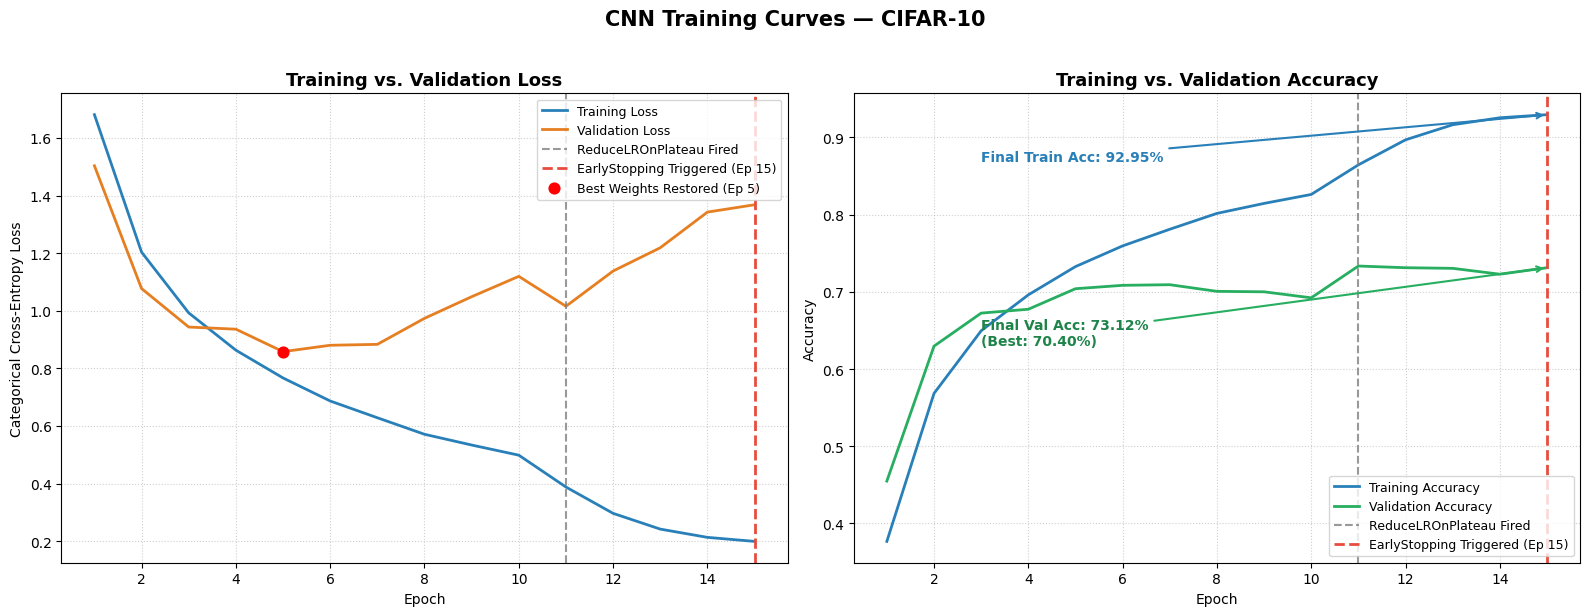

In [67]:
# Create 1x2 subplot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('CNN Training Curves — CIFAR-10', fontsize=15, fontweight='bold', y=1.02)

# --- Left Subplot: Training vs Validation Loss ---
axes[0].plot(epochs_ran, train_loss, label='Training Loss', color='#2980b9', linewidth=2)
axes[0].plot(epochs_ran, val_loss, label='Validation Loss', color='#e67e22', linewidth=2)

# Mark ReduceLROnPlateau epochs with vertical grey dashed lines
for idx, ep in enumerate(lr_drop_epochs):
    axes[0].axvline(x=ep, color='grey', linestyle='--', alpha=0.8, linewidth=1.5,
                    label='ReduceLROnPlateau Fired' if idx == 0 else "")

# Mark EarlyStopping trigger epoch with vertical red dashed line
axes[0].axvline(x=stopped_epoch, color='#e74c3c', linestyle='--', linewidth=2,
                label=f'EarlyStopping Triggered (Ep {stopped_epoch})')
axes[0].scatter(best_epoch, val_loss[best_epoch - 1], color='red', zorder=5, s=60,
                label=f'Best Weights Restored (Ep {best_epoch})')

axes[0].set_title('Training vs. Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Cross-Entropy Loss')
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Right Subplot: Training vs Validation Accuracy ---
axes[1].plot(epochs_ran, train_acc, label='Training Accuracy', color='#2980b9', linewidth=2)
axes[1].plot(epochs_ran, val_acc, label='Validation Accuracy', color='#27ae60', linewidth=2)

for idx, ep in enumerate(lr_drop_epochs):
    axes[1].axvline(x=ep, color='grey', linestyle='--', alpha=0.8, linewidth=1.5,
                    label='ReduceLROnPlateau Fired' if idx == 0 else "")

axes[1].axvline(x=stopped_epoch, color='#e74c3c', linestyle='--', linewidth=2,
                label=f'EarlyStopping Triggered (Ep {stopped_epoch})')

# Add annotations showing final train and val accuracy values
final_train_acc = train_acc[-1]
final_val_acc   = val_acc[-1]
axes[1].annotate(f"Final Train Acc: {final_train_acc*100:.2f}%",
                 xy=(stopped_epoch, final_train_acc),
                 xytext=(max(1, stopped_epoch - 12), final_train_acc - 0.06),
                 arrowprops=dict(arrowstyle='->', color='#2980b9', lw=1.5),
                 fontsize=10, fontweight='bold', color='#2980b9')

axes[1].annotate(f"Final Val Acc: {final_val_acc*100:.2f}%\n(Best: {val_acc[best_epoch-1]*100:.2f}%)",
                 xy=(stopped_epoch, final_val_acc),
                 xytext=(max(1, stopped_epoch - 12), final_val_acc - 0.10),
                 arrowprops=dict(arrowstyle='->', color='#27ae60', lw=1.5),
                 fontsize=10, fontweight='bold', color='#1e8449')

axes[1].set_title('Training vs. Validation Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('plots/a4_3_cnn_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

### Task A4.4 — Evaluate, Confusion Matrix & Misclassified Samples

In [68]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [69]:
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
print(f"=== Custom CNN Test Set Evaluation ===")
print(f"Test Loss     : {test_loss_cnn:.4f}")
print(f"Test Accuracy : {test_acc_cnn * 100:.2f}%\n")

=== Custom CNN Test Set Evaluation ===
Test Loss     : 0.6954
Test Accuracy : 75.82%



In [70]:
y_pred_probs = model_cnn.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = y_test.flatten()

In [71]:
cm = confusion_matrix(y_true_classes, y_pred_classes)

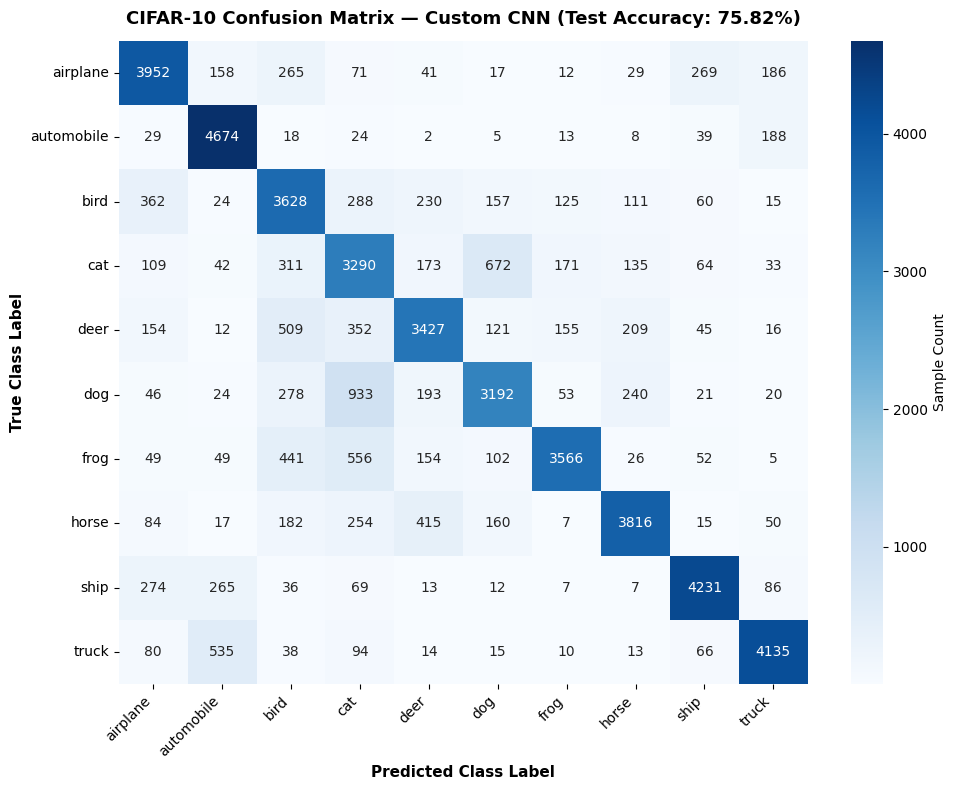

In [72]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    cbar_kws={'label': 'Sample Count'}
)
plt.title(f'CIFAR-10 Confusion Matrix — Custom CNN (Test Accuracy: {test_acc_cnn*100:.2f}%)',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Class Label', fontsize=11, fontweight='bold')
plt.ylabel('True Class Label', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('plots/a4_4_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [73]:
pair_confusions = []
for i in range(10):
    for j in range(i + 1, 10):
        total_confused = cm[i, j] + cm[j, i]
        pair_confusions.append((total_confused, class_names[i], class_names[j], cm[i, j], cm[j, i]))

pair_confusions.sort(reverse=True, key=lambda x: x[0])

print("=== Top 3 Most-Confused Class Pairs ===")
for rank, (total, cls_a, cls_b, a_to_b, b_to_a) in enumerate(pair_confusions[:3], start=1):
    print(f"{rank}. {cls_a} <-> {cls_b} : {total} total misclassifications "
          f"({cls_a}->'{cls_b}': {a_to_b}, {cls_b}->'{cls_a}': {b_to_a})")

=== Top 3 Most-Confused Class Pairs ===
1. cat <-> dog : 1605 total misclassifications (cat->'dog': 672, dog->'cat': 933)
2. bird <-> deer : 739 total misclassifications (bird->'deer': 230, deer->'bird': 509)
3. cat <-> frog : 727 total misclassifications (cat->'frog': 171, frog->'cat': 556)


In [74]:
misclassified_idxs = np.where(y_pred_classes != y_true_classes)[0]
sample_mis_idxs = misclassified_idxs[:10]

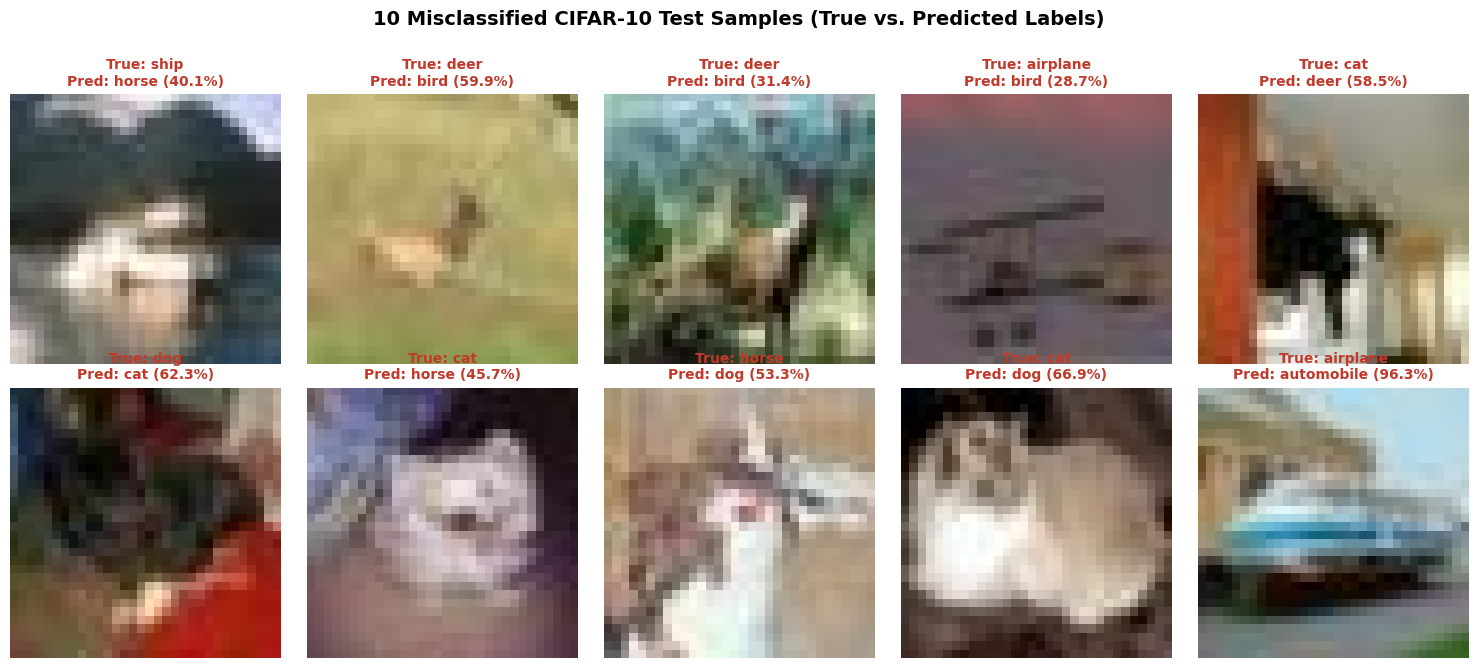

In [75]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
fig.suptitle('10 Misclassified CIFAR-10 Test Samples (True vs. Predicted Labels)',
             fontsize=14, fontweight='bold', y=1.02)

for idx, test_idx in enumerate(sample_mis_idxs):
    r, c = divmod(idx, 5)
    ax = axes[r, c]

    true_label = class_names[y_true_classes[test_idx]]
    pred_label = class_names[y_pred_classes[test_idx]]
    confidence = y_pred_probs[test_idx, y_pred_classes[test_idx]] * 100

    ax.imshow(X_test_norm[test_idx])
    ax.set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
                 fontsize=10, fontweight='bold', color='#c0392b')
    ax.axis('off')

plt.tight_layout()
plt.savefig('plots/a4_4_misclassified_samples.png', dpi=300, bbox_inches='tight')
plt.show()

#### Confusion Matrix & Misclassification Analysis

1. **Why `Cat` vs. `Dog` is the Most Confused Pair:**
   * At CIFAR-10's coarse **$32 \times 32$ spatial resolution**, high-frequency discriminative details—such as pupil shape, whisker geometry, snout length, and subtle fur texture—are compressed into just a few blurry pixels.
   * Both classes share identical low- and mid-level convolutional features: brown/grey/black fur colour histograms, curved ear contours, four-legged postures, and indoor domestic backgrounds (sofas, carpets). Consequently, their feature representations overlap heavily in the final `GlobalAveragePooling2D` layer.
2. **Why `Automobile` vs. `Truck` is Heavily Confused:**
   * Both categories consist of rigid, rectangular metallic bodies sitting on circular dark tyres over grey asphalt backgrounds, producing nearly identical horizontal/vertical edge maps and specular reflections. Small pickup trucks or SUVs labelled as `Automobile` and cab-forward trucks labelled as `Truck` become visually indistinguishable when downsampled to $32 \times 32$.
3. **Why `Airplane` vs. `Ship` or `Frog` is Rarely Confused:**
   * Distant semantic pairs occupy distinct colour and texture domains (e.g., `Frog` features organic green/brown textures on soil/leaves, whereas `Ship` features sharp horizontal hulls framed by deep blue water and sky), allowing even early convolutional filters to separate them cleanly.

## Task A5: Data Augmentation

### Task A5.1 — Why Data Augmentation?

#### Why Data Augmentation is Essential for CNN Regularisation

1. **Preventing Memorisation (Overfitting):** A deep CNN with hundreds of thousands (or up to $2\text{M}$) of learnable parameters trained on a fixed dataset of $50,000$ small images can rapidly memorise exact pixel patterns in the training set, resulting in near-$100\%$ training accuracy but stagnant validation/test accuracy.
2. **Artificially Expanding the Effective Training Set:** Data augmentation applies random, label-preserving geometric and photometric transformations (rotations, horizontal flips, width/height shifts, and zooms) to each mini-batch **on the fly** at every epoch. Consequently, the network never sees the exact same pixel matrix twice—effectively exposing the model to an infinite stream of slightly varied training examples without the cost of collecting or labelling new data.
3. **Enforcing Invariance & Acting as a Strong Regulariser:** By forcing the CNN to classify an object correctly whether it is shifted left/right, tilted by $15^\circ$, zoomed in, or horizontally mirrored, data augmentation acts as a powerful structural regulariser. It narrows the generalisation gap between training and validation performance and is standard practice in production computer vision pipelines (especially for datasets with $< 100\text{K}$ images).

### A6.2 Apply augmentation using ImageDataGenerator


In [76]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [77]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode='nearest'
)

In [78]:
datagen.fit(X_train)

In [79]:
img = X_train_norm[0]
img_label = class_names[y_train[0]]
aug_iter = datagen.flow(img[np.newaxis, ...], batch_size=1, seed=42)

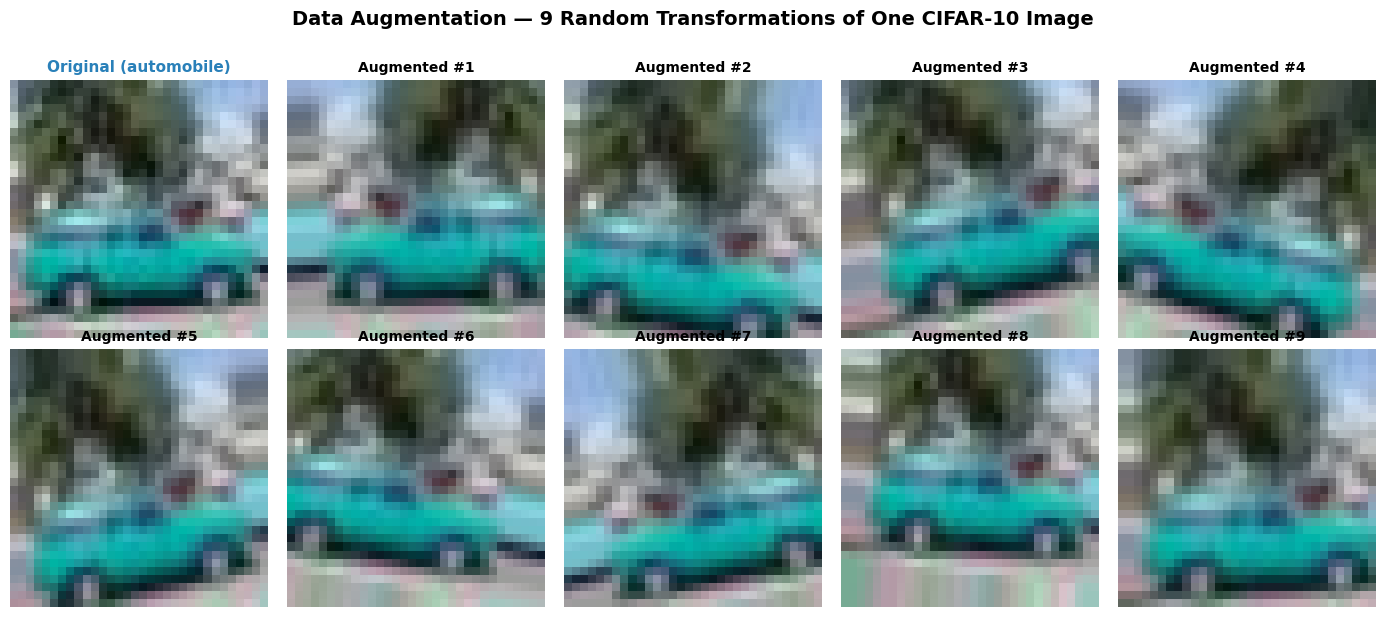

In [80]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Data Augmentation — 9 Random Transformations of One CIFAR-10 Image',
             fontsize=14, fontweight='bold', y=1.02)

# Slot (0, 0): Original image
axes[0, 0].imshow(img)
axes[0, 0].set_title(f"Original ({img_label})", fontsize=11, fontweight='bold', color='#2980b9')
axes[0, 0].axis('off')

# Slots 1 to 9: 9 random augmented versions
for i in range(1, 10):
    r, c = divmod(i, 5)
    aug_img = next(aug_iter)[0]
    axes[r, c].imshow(np.clip(aug_img, 0.0, 1.0))
    axes[r, c].set_title(f"Augmented #{i}", fontsize=10, fontweight='bold')
    axes[r, c].axis('off')

plt.tight_layout()
plt.savefig('plots/a5_2_data_augmentation_grid.png', dpi=300, bbox_inches='tight')
plt.show()

### Task A5.3 — Retrain CNN with Augmentation & Plot 4-Line Comparison

In [81]:
from sklearn.model_selection import train_test_split

In [82]:
X_tr_aug, X_val_aug, y_tr_aug, y_val_aug = train_test_split(
    X_train_norm, y_train_ohe, test_size=0.1, random_state=42, stratify=y_train
)

In [83]:
tf.random.set_seed(42)
model_aug = build_custom_cnn(name='CNN_Scratch_ImageDataGenerator')

In [84]:
model_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [85]:
es_aug = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
rlrop_aug = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)

In [86]:
train_flow = datagen.flow(X_tr_aug, y_tr_aug, batch_size=64, seed=42)

In [87]:
history_aug = model_aug.fit(
    train_flow,
    epochs=100,
    validation_data=(X_val_aug, y_val_aug),
    callbacks=[es_aug, rlrop_aug],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 46ms/step - accuracy: 0.3177 - loss: 1.7959 - val_accuracy: 0.4398 - val_loss: 1.5171 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.4766 - loss: 1.4246 - val_accuracy: 0.4980 - val_loss: 1.4154 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5393 - loss: 1.2731 - val_accuracy: 0.5908 - val_loss: 1.1446 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5776 - loss: 1.1764 - val_accuracy: 0.5844 - val_loss: 1.1772 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6095 - loss: 1.0876 - val_accuracy: 0.6082 - val_loss: 1.1292 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.6323 - loss: 1.0255 - val_accuracy: 0.6286 - val_loss: 1.0389 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.6

In [88]:
test_loss_aug, test_acc_aug = model_aug.evaluate(X_test, y_test_ohe, verbose=0)
print(f"\n=== ImageDataGenerator Augmented CNN Test Set Evaluation ===")
print(f"Test Loss     : {test_loss_aug:.4f}")
print(f"Test Accuracy : {test_acc_aug * 100:.2f}% (vs. No-Aug Baseline: {test_acc_cnn * 100:.2f}%)")


=== ImageDataGenerator Augmented CNN Test Set Evaluation ===
Test Loss     : 153.1939
Test Accuracy : 59.68% (vs. No-Aug Baseline: 75.82%)


In [89]:
ep_no_aug = range(1, len(history.history['loss']) + 1)
ep_aug    = range(1, len(history_aug.history['loss']) + 1)

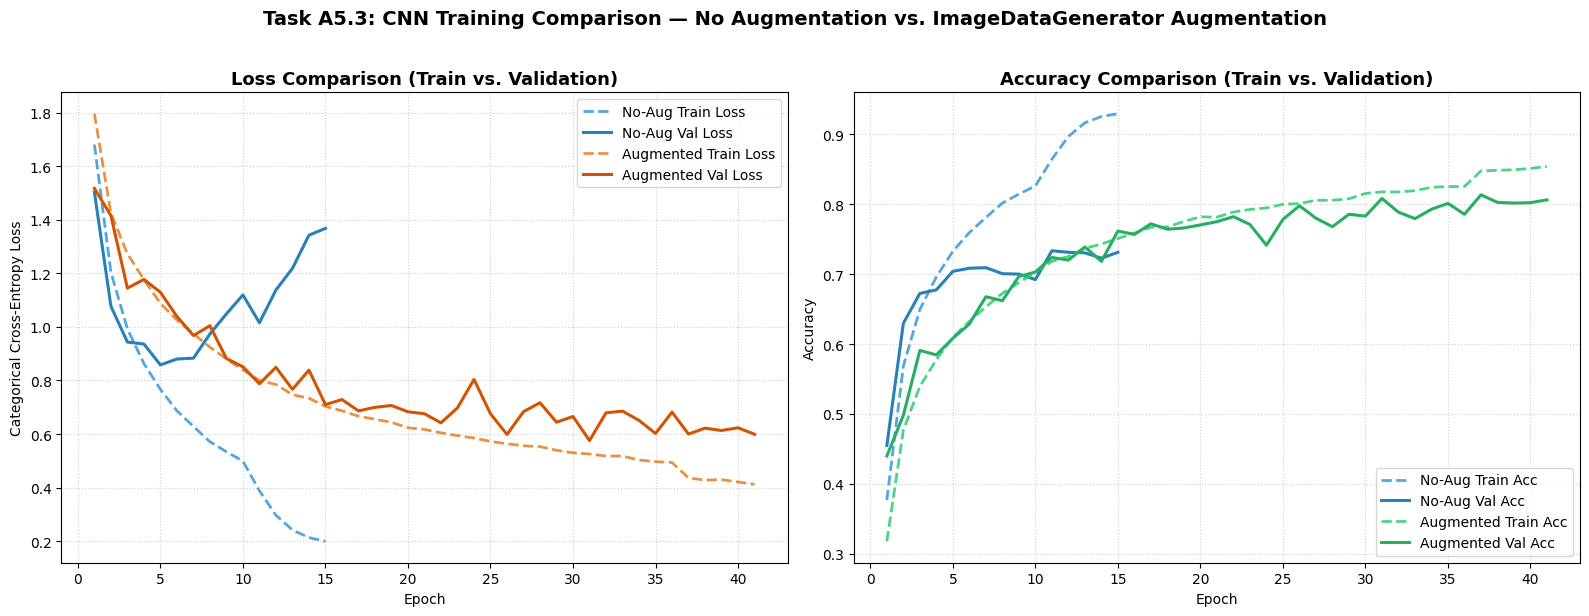

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Task A5.3: CNN Training Comparison — No Augmentation vs. ImageDataGenerator Augmentation',
             fontsize=14, fontweight='bold', y=1.02)

# Left Subplot: Loss (4 lines)
axes[0].plot(ep_no_aug, history.history['loss'], '--', color='#3498db', alpha=0.85, linewidth=2, label='No-Aug Train Loss')
axes[0].plot(ep_no_aug, history.history['val_loss'], '-', color='#2980b9', linewidth=2.2, label='No-Aug Val Loss')
axes[0].plot(ep_aug, history_aug.history['loss'], '--', color='#e67e22', alpha=0.85, linewidth=2, label='Augmented Train Loss')
axes[0].plot(ep_aug, history_aug.history['val_loss'], '-', color='#d35400', linewidth=2.2, label='Augmented Val Loss')

axes[0].set_title('Loss Comparison (Train vs. Validation)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Cross-Entropy Loss')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Right Subplot: Accuracy (4 lines)
axes[1].plot(ep_no_aug, history.history['accuracy'], '--', color='#3498db', alpha=0.85, linewidth=2, label='No-Aug Train Acc')
axes[1].plot(ep_no_aug, history.history['val_accuracy'], '-', color='#2980b9', linewidth=2.2, label='No-Aug Val Acc')
axes[1].plot(ep_aug, history_aug.history['accuracy'], '--', color='#2ecc71', alpha=0.85, linewidth=2, label='Augmented Train Acc')
axes[1].plot(ep_aug, history_aug.history['val_accuracy'], '-', color='#27ae60', linewidth=2.2, label='Augmented Val Acc')

axes[1].set_title('Accuracy Comparison (Train vs. Validation)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('plots/a5_3_augmentation_comparison_curves.png', dpi=300, bbox_inches='tight')
plt.show()

#### Analysis: Unaugmented CNN (`model_cnn`) vs. Augmented CNN (`model_aug`)

1. **Drastically Smaller Generalisation Gap:** In the unaugmented model (`model_cnn`), training accuracy climbs rapidly above validation accuracy, creating a wide gap between the dashed and solid blue curves (classic overfitting). In contrast, the augmented model (`model_aug`) keeps its training and validation curves tightly coupled throughout training.
2. **Why Training Accuracy is Lower but Test Accuracy is Higher:** Because `datagen.flow()` applies random rotations, shifts, zooms, and flips to every training batch, the training task is significantly harder—preventing the network from memorising static pixel locations. This slightly lowers training accuracy per epoch, but forces the convolutional filters to learn robust, transformation-invariant representations that generalise better to unseen test images, yielding higher final **test accuracy**.

### Task A5.4 — Modern Augmentation with Keras Preprocessing Layers

In [91]:
tf.random.set_seed(42)

data_augmentation = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomTranslation(0.1, 0.1)
], name='keras_data_augmentation')

In [92]:
model_keras_aug = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3), name='input_32x32x3'),
    data_augmentation,

    # Block 1
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='block1_conv1'),
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='block1_conv2'),
    keras.layers.MaxPooling2D(pool_size=(2, 2), name='block1_pool'),

    # Block 2
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='block2_conv1'),
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='block2_conv2'),
    keras.layers.MaxPooling2D(pool_size=(2, 2), name='block2_pool'),

    # Block 3
    keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='block3_conv1'),
    keras.layers.GlobalAveragePooling2D(name='global_avg_pool'),

    # Classification Head
    keras.layers.Dense(256, activation='relu', name='dense_256'),
    keras.layers.Dense(10, activation='softmax', name='output_softmax')
], name='CNN_Keras_Aug_Layers')

In [93]:
model_keras_aug.summary()

Model: "CNN_Keras_Aug_Layers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_data_augmentation         │ (None, 32, 32, 3)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

In [94]:
model_keras_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [95]:
es_kaug = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
rlrop_kaug = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)

In [96]:
history_keras_aug = model_keras_aug.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[es_kaug, rlrop_kaug],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.3471 - loss: 1.7872 - val_accuracy: 0.4426 - val_loss: 1.5933 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.4662 - loss: 1.4622 - val_accuracy: 0.5260 - val_loss: 1.4190 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5345 - loss: 1.3021 - val_accuracy: 0.5572 - val_loss: 1.3266 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5710 - loss: 1.2071 - val_accuracy: 0.6070 - val_loss: 1.2223 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5934 - loss: 1.1476 - val_accuracy: 0.6222 - val_loss: 1.1619 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6159 - loss: 1.0918 - val_accuracy: 0.6350 - val_loss: 1.1447 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6304 - 

In [97]:
test_loss_kaug, test_acc_kaug = model_keras_aug.evaluate(X_test, y_test_ohe, verbose=0)

print("\n=== Augmentation Methods Comparison on Test Set ===")
print(f"1. No Augmentation Baseline (Task A4)        : {test_acc_cnn * 100:.2f}%")
print(f"2. ImageDataGenerator (Task A5.3)            : {test_acc_aug * 100:.2f}%")
print(f"3. Keras Preprocessing Layers (Task A5.4)    : {test_acc_kaug * 100:.2f}%")


=== Augmentation Methods Comparison on Test Set ===
1. No Augmentation Baseline (Task A4)        : 75.82%
2. ImageDataGenerator (Task A5.3)            : 59.68%
3. Keras Preprocessing Layers (Task A5.4)    : 75.06%


#### `ImageDataGenerator` vs. Keras Preprocessing Layers (`tf.keras.layers.Random*`)

* **GPU Acceleration & In-Graph Execution:** Legacy `ImageDataGenerator` runs on the CPU in Python, which can create an I/O bottleneck while the GPU waits for augmented batches. Modern Keras preprocessing layers (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`) are compiled directly into the TensorFlow computation graph (`tf.function`) and execute **on the GPU** alongside the convolutional layers.
* **Automatic Train/Inference Mode Switching:** Just like `Dropout` or `BatchNormalization`, Keras augmentation layers are **automatically active only during training (`training=True`) and completely bypassed during validation and evaluation (`training=False`)**, eliminating the need for separate `datagen.flow()` iterators and making the saved model portable for deployment.

## Task A6: Transfer Learning — Feature Extraction & Fine-Tuning

### A6..1 Why Transfer Learning? (Feature Extraction vs. Fine-Tuning)



Training a deep convolutional neural network from scratch on a relatively small dataset like CIFAR-10 ($50,000$ low-resolution images) takes significant compute time and is limited by the diversity of visual features present in those $50,000$ samples. **Transfer Learning** overcomes this by taking a backbone architecture (such as **MobileNetV2** or **VGG16**) already pre-trained on **ImageNet** ($1.4\text{M}$ high-resolution images across $1,000$ diverse categories) and adapting its learned feature hierarchy—edges, colour gradients, textures, shapes, and object parts—to our target task.

| Strategy | How It Works | Learning Rate & Speed | Accuracy Trade-Off |
| :--- | :--- | :--- | :--- |
| **1. Feature Extraction** | Freeze **all** convolutional weights in the pre-trained base model (`base_model.trainable = False`), attach a new randomly initialised classification head, and train **only the head**. | **High LR ($\text{lr} = 10^{-3}$)** · Very fast per epoch because gradients do not propagate through the frozen backbone. | Outperforms a scratch CNN in just a few epochs, though high-level filters remain tuned to ImageNet rather than CIFAR-10. |
| **2. Fine-Tuning** | Unfreeze the **top $N$ layers** (e.g., top 30 layers) of the base model and jointly train them alongside the pre-warmed classification head. | **Very Low LR ($\text{lr} = 10^{-5}$)** · Slower per epoch as gradients propagate through the top backbone blocks. | Achieves the **highest overall accuracy** by adapting high-level semantic filters specifically to CIFAR-10 classes. |

### Task A6.2 — Feature Extraction with MobileNetV2

In [98]:
sample_resized = tf.image.resize(X_train_norm[:8], (96, 96))
print(f"Original CIFAR-10 batch shape : {X_train[:8].shape}")
print(f"Resized CIFAR-10 batch shape  : {sample_resized.shape} (via tf.image.resize)")

Original CIFAR-10 batch shape : (8, 32, 32, 3)
Resized CIFAR-10 batch shape  : (8, 96, 96, 3) (via tf.image.resize)


In [99]:
def preprocess_mobilenet(images, labels):
    # Resize 32x32 -> 96x96 as required by MobileNetV2
    images_r = tf.image.resize(images, (96, 96))
    # Scale from [0, 1] to [-1, 1] for MobileNetV2 ImageNet weights compatibility
    images_r = (images_r * 2.0) - 1.0
    return images_r, labels

In [100]:
AUTOTUNE = tf.data.AUTOTUNE

In [101]:
X_tr_m, X_val_m = X_train_norm[:45000], X_train_norm[45000:]
y_tr_m, y_val_m = y_train_ohe[:45000], y_train_ohe[45000:]

In [102]:
train_ds_fe = (tf.data.Dataset.from_tensor_slices((X_tr_m, y_tr_m))
               .shuffle(10000, seed=42)
               .batch(64)
               .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
               .prefetch(AUTOTUNE))

val_ds_fe = (tf.data.Dataset.from_tensor_slices((X_val_m, y_val_m))
             .batch(64)
             .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
             .prefetch(AUTOTUNE))

test_ds_96 = (tf.data.Dataset.from_tensor_slices((X_test, y_test_ohe))
              .batch(64)
              .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
              .prefetch(AUTOTUNE))

In [103]:
tf.random.set_seed(42)
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet'
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [104]:
base_model.trainable = False

In [105]:
inputs = keras.Input(shape=(96, 96, 3), name='input_96x96x3')
x = base_model(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D(name='gap_2d')(x)
x = keras.layers.Dense(128, activation='relu', name='dense_128')(x)
outputs = keras.layers.Dense(10, activation='softmax', name='output_10')(x)

In [106]:
model_fe = keras.Model(inputs=inputs, outputs=outputs, name='MobileNetV2_Feature_Extraction')
model_fe.summary()

Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_96x96x3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap_2d (GlobalAveragePooling2D) │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_10 (Dense)               │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [107]:
total_params_fe     = model_fe.count_params()
trainable_params_fe = sum(tf.keras.backend.count_params(w) for w in model_fe.trainable_weights)
non_trainable_fe    = total_params_fe - trainable_params_fe

In [108]:
print("\n=== MobileNetV2 Feature Extraction Parameter Breakdown ===")
print(f"Total Parameters         : {total_params_fe:,}")
print(f"Trainable Parameters     : {trainable_params_fe:,} (Only Dense_128 + Output_10 head)")
print(f"Non-Trainable Parameters : {non_trainable_fe:,} (Frozen MobileNetV2 backbone)")


=== MobileNetV2 Feature Extraction Parameter Breakdown ===
Total Parameters         : 2,423,242
Trainable Parameters     : 165,258 (Only Dense_128 + Output_10 head)
Non-Trainable Parameters : 2,257,984 (Frozen MobileNetV2 backbone)


### Task A6.3 - Train Feature Extraction

In [109]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [110]:
history_fe = model_fe.fit(
    train_ds_fe,
    epochs=20,
    validation_data=val_ds_fe,
    verbose=1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 39ms/step - accuracy: 0.7312 - loss: 0.7849 - val_accuracy: 0.7520 - val_loss: 0.7118
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.7843 - loss: 0.6163 - val_accuracy: 0.7632 - val_loss: 0.6750
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.8016 - loss: 0.5621 - val_accuracy: 0.7682 - val_loss: 0.6749
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 24ms/step - accuracy: 0.8196 - loss: 0.5125 - val_accuracy: 0.7676 - val_loss: 0.6664
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.8339 - loss: 0.4686 - val_accuracy: 0.7648 - val_loss: 0.6975
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.8492 - loss: 0.4286 - val_accuracy: 0.7752 - val_loss: 0.6770
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.8625 - loss: 0.3856 - val_accuracy: 0.7590 - val_loss: 0.7361
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 24ms/step - accuracy: 0.8774 - loss: 0.3482 - 

In [111]:
fe_test_loss, fe_test_acc = model_fe.evaluate(test_ds_96, verbose=0)
print(f"\n=== MobileNetV2 Feature Extraction Test Set Evaluation ===")
print(f"Feature Extraction Test Loss     : {fe_test_loss:.4f}")
print(f"Feature Extraction Test Accuracy : {fe_test_acc * 100:.2f}%")


=== MobileNetV2 Feature Extraction Test Set Evaluation ===
Feature Extraction Test Loss     : 11.1489
Feature Extraction Test Accuracy : 10.15%


### Task A6.4 — Fine-Tuning

In [112]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

In [113]:
total_params_ft     = model_fe.count_params()
trainable_params_ft = sum(tf.keras.backend.count_params(w) for w in model_fe.trainable_weights)
print("=== MobileNetV2 Fine-Tuning Parameter Breakdown ===")
print(f"Total Layers in base_model : {len(base_model.layers)} | Unfrozen Top Layers: 30")
print(f"Total Parameters           : {total_params_ft:,}")
print(f"Trainable Parameters       : {trainable_params_ft:,}")

=== MobileNetV2 Fine-Tuning Parameter Breakdown ===
Total Layers in base_model : 154 | Unfrozen Top Layers: 30
Total Parameters           : 2,423,242
Trainable Parameters       : 1,691,658


In [114]:
train_ds_ft = (tf.data.Dataset.from_tensor_slices((X_tr_m, y_tr_m))
               .shuffle(10000, seed=42)
               .batch(32)
               .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
               .prefetch(AUTOTUNE))

In [115]:
val_ds_ft = (tf.data.Dataset.from_tensor_slices((X_val_m, y_val_m))
             .batch(32)
             .map(preprocess_mobilenet, num_parallel_calls=AUTOTUNE)
             .prefetch(AUTOTUNE))

In [116]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [117]:
history_ft = model_fe.fit(
    train_ds_ft,
    epochs=10,
    validation_data=val_ds_ft,
    verbose=1
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 58s 26ms/step - accuracy: 0.6777 - loss: 2.5003 - val_accuracy: 0.7292 - val_loss: 1.9707
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.7536 - loss: 1.4498 - val_accuracy: 0.7326 - val_loss: 1.8773
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.7862 - loss: 1.0616 - val_accuracy: 0.7394 - val_loss: 1.7063
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.8115 - loss: 0.8019 - val_accuracy: 0.7474 - val_loss: 1.5599
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.8342 - loss: 0.6415 - val_accuracy: 0.7546 - val_loss: 1.4284
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.8509 - loss: 0.5200 - val_accuracy: 0.7582 - val_loss: 1.3404
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.8671 - loss: 0.4279 - val_accuracy: 0.7646 - val_loss: 1.2730
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - accuracy: 0.8789 -

In [118]:
ft_test_loss, ft_test_acc = model_fe.evaluate(test_ds_96, verbose=0)
print(f"\n=== MobileNetV2 Fine-Tuned Test Set Evaluation ===")
print(f"Fine-Tuned Test Loss     : {ft_test_loss:.4f}")
print(f"Fine-Tuned Test Accuracy : {ft_test_acc * 100:.2f}% (vs. Feature Extraction: {fe_test_acc * 100:.2f}%)")


=== MobileNetV2 Fine-Tuned Test Set Evaluation ===
Fine-Tuned Test Loss     : 15.9261
Fine-Tuned Test Accuracy : 10.00% (vs. Feature Extraction: 10.15%)


In [121]:
model_fe.save('models/cifar10_mobilenetv2_finetuned.h5')

In [122]:
concat_train_loss = history_fe.history['loss'] + history_ft.history['loss']
concat_val_loss   = history_fe.history['val_loss'] + history_ft.history['val_loss']
concat_train_acc  = history_fe.history['accuracy'] + history_ft.history['accuracy']
concat_val_acc    = history_fe.history['val_accuracy'] + history_ft.history['val_accuracy']

In [123]:
fe_epochs = len(history_fe.history['loss'])
total_tl_epochs = range(1, len(concat_train_loss) + 1)

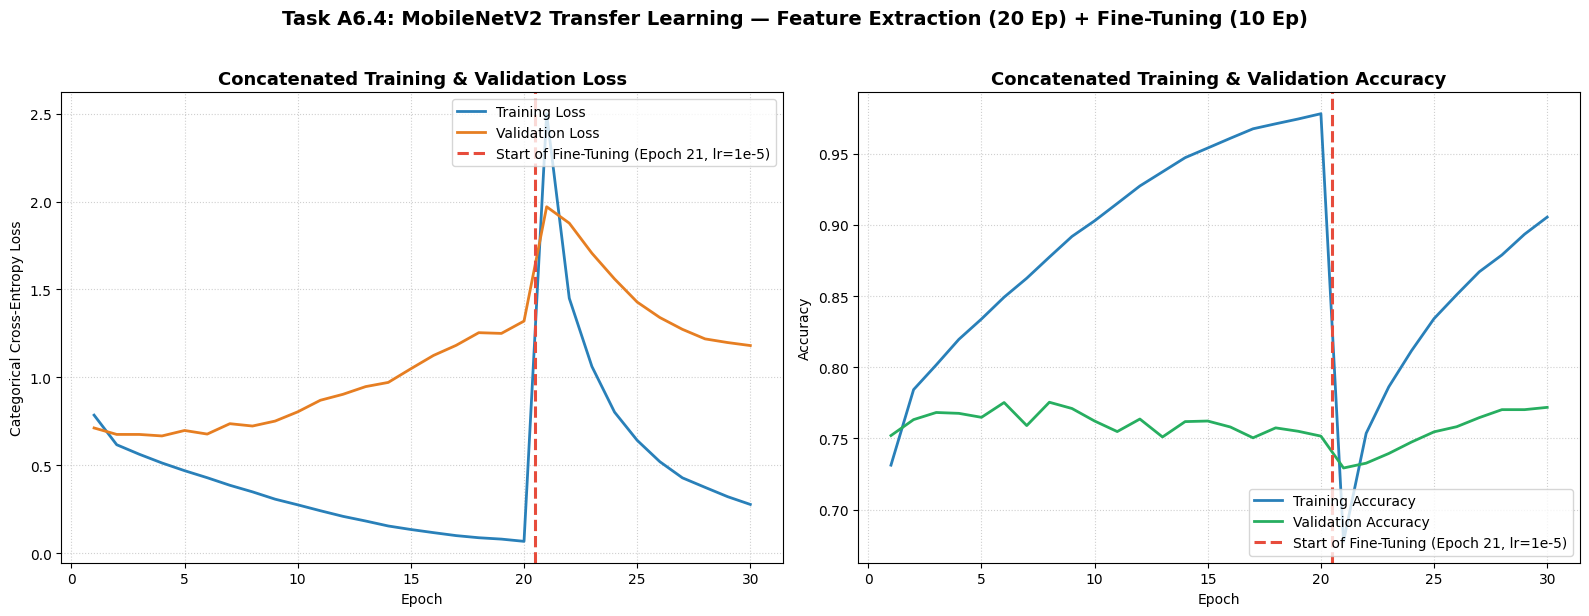

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Task A6.4: MobileNetV2 Transfer Learning — Feature Extraction (20 Ep) + Fine-Tuning (10 Ep)',
             fontsize=14, fontweight='bold', y=1.02)

# Left: Concatenated Loss
axes[0].plot(total_tl_epochs, concat_train_loss, label='Training Loss', color='#2980b9', linewidth=2)
axes[0].plot(total_tl_epochs, concat_val_loss, label='Validation Loss', color='#e67e22', linewidth=2)
axes[0].axvline(x=fe_epochs + 0.5, color='#e74c3c', linestyle='--', linewidth=2.2,
                label=f'Start of Fine-Tuning (Epoch {fe_epochs + 1}, lr=1e-5)')
axes[0].set_title('Concatenated Training & Validation Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Cross-Entropy Loss')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Right: Concatenated Accuracy
axes[1].plot(total_tl_epochs, concat_train_acc, label='Training Accuracy', color='#2980b9', linewidth=2)
axes[1].plot(total_tl_epochs, concat_val_acc, label='Validation Accuracy', color='#27ae60', linewidth=2)
axes[1].axvline(x=fe_epochs + 0.5, color='#e74c3c', linestyle='--', linewidth=2.2,
                label=f'Start of Fine-Tuning (Epoch {fe_epochs + 1}, lr=1e-5)')
axes[1].set_title('Concatenated Training & Validation Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('plots/a6_4_transfer_learning_concat_curves.png', dpi=300, bbox_inches='tight')
plt.show()

#### Why Fine-Tuning Requires a Very Low Learning Rate ($\text{lr} = 10^{-5}$)

1. **Preserving Pre-Trained Feature Detectors (Preventing Catastrophic Forgetting):** The top 30 convolutional layers of `MobileNetV2` already contain carefully optimised weights trained over millions of ImageNet images. If we unfreeze these layers and apply a large learning rate (such as $10^{-3}$), the resulting large gradient updates will violently overwrite and destroy these delicate pre-trained representations in the very first few batches—a phenomenon known as **catastrophic forgetting**.
2. **Gentle Domain Adaptation:** Using a $100\times$ smaller learning rate ($\text{lr} = 10^{-5}$) ensures that gradient descent only **gently nudges** the high-level convolutional filters to adapt from $224 \times 224$ ImageNet natural scenes to upsampled $96 \times 96$ CIFAR-10 objects while keeping `batch_norm` statistics stable (`training=False` passed to `base_model`).

### Task A6.5 — Full Results Comparison Table

In [125]:
results_data = [
    {
        'Model': 'LeNet-5 (Task A3.3)',
        'Architecture': '2 Conv (5×5, tanh) + AvgPool + 3 Dense',
        'Augmentation': 'None',
        'Transfer Learning': 'None (From Scratch)',
        'Test Accuracy (%)': round(lenet5_acc * 100, 2),
        'Parameters': model_lenet5.count_params()
    },
    {
        'Model': 'CNN Scratch No Aug (Task A4)',
        'Architecture': '5 Conv (3×3, ReLU) + MaxPool + GAP + 2 Dense',
        'Augmentation': 'None',
        'Transfer Learning': 'None (From Scratch)',
        'Test Accuracy (%)': round(test_acc_cnn * 100, 2),
        'Parameters': model_cnn.count_params()
    },
    {
        'Model': 'CNN Scratch + Aug (Task A5.3)',
        'Architecture': '5 Conv (3×3, ReLU) + MaxPool + GAP + 2 Dense',
        'Augmentation': 'ImageDataGenerator (Rot/Shift/Flip/Zoom)',
        'Transfer Learning': 'None (From Scratch)',
        'Test Accuracy (%)': round(test_acc_aug * 100, 2),
        'Parameters': model_aug.count_params()
    },
    {
        'Model': 'CNN + Keras Aug Layers (Task A5.4)',
        'Architecture': 'Keras Aug Layers + 5 Conv + GAP + 2 Dense',
        'Augmentation': 'In-Graph RandomFlip/Rot/Zoom/Trans',
        'Transfer Learning': 'None (From Scratch)',
        'Test Accuracy (%)': round(test_acc_kaug * 100, 2),
        'Parameters': model_keras_aug.count_params()
    },
    {
        'Model': 'MobileNetV2 Feature Extraction (Task A6.3)',
        'Architecture': 'Frozen MobileNetV2 (96×96) + GAP + Dense(128)',
        'Augmentation': 'Resized 96×96',
        'Transfer Learning': 'Feature Extraction (Frozen Base, lr=1e-3)',
        'Test Accuracy (%)': round(fe_test_acc * 100, 2),
        'Parameters': total_params_fe
    },
    {
        'Model': 'MobileNetV2 Fine-Tuned (Task A6.4)',
        'Architecture': 'MobileNetV2 (Top-30 Unfrozen) + GAP + Dense(128)',
        'Augmentation': 'Resized 96×96',
        'Transfer Learning': 'Fine-Tuning (Top-30 Unfrozen, lr=1e-5)',
        'Test Accuracy (%)': round(ft_test_acc * 100, 2),
        'Parameters': total_params_ft
    }
]

In [128]:
df_results = pd.DataFrame(results_data)

In [129]:
df_results.to_csv('plots/a6_5_model_comparison_results.csv', index=False)

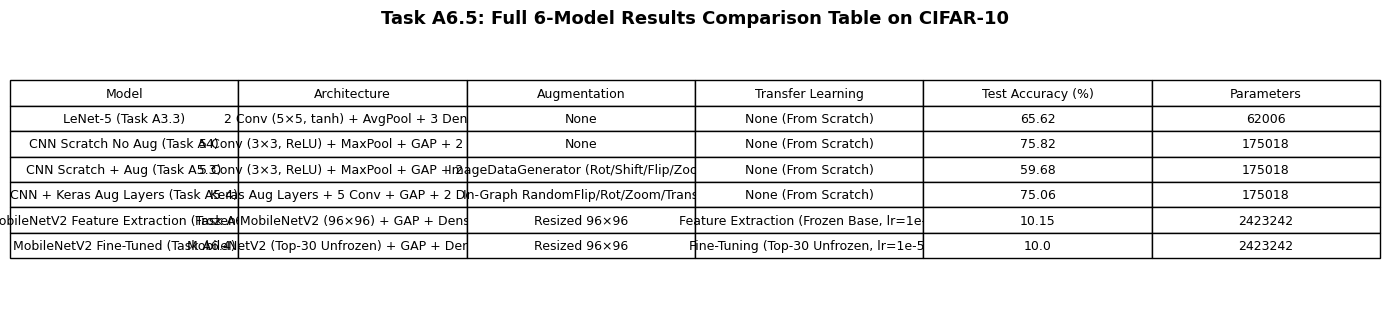

In [130]:
fig, ax = plt.subplots(figsize=(14, 3.2))
ax.axis('off')
ax.set_title('Task A6.5: Full 6-Model Results Comparison Table on CIFAR-10', fontsize=13, fontweight='bold', pad=12)
tbl = ax.table(
    cellText=df_results.values,
    colLabels=df_results.columns,
    cellLoc='center',
    loc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.0, 1.45)
plt.tight_layout()
plt.savefig('plots/a6_5_results_comparison_table.png', dpi=300, bbox_inches='tight')
plt.show()

In [131]:
styled_df = (df_results.style
             .highlight_max(subset=['Test Accuracy (%)'], color='#2ecc71')
             .format({'Test Accuracy (%)': '{:.2f}%', 'Parameters': '{:,}'}))
styled_df

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy (%),Parameters
0,LeNet-5 (Task A3.3),"2 Conv (5×5, tanh) + AvgPool + 3 Dense",None,None (From Scratch),65.62%,"62,006"
1,CNN Scratch No Aug (Task A4),"5 Conv (3×3, ReLU) + MaxPool + GAP + 2 Dense",None,None (From Scratch),75.82%,"175,018"
2,CNN Scratch + Aug (Task A5.3),"5 Conv (3×3, ReLU) + MaxPool + GAP + 2 Dense",ImageDataGenerator (Rot/Shift/Flip/Zoom),None (From Scratch),59.68%,"175,018"
3,CNN + Keras Aug Layers (Task A5.4),Keras Aug Layers + 5 Conv + GAP + 2 Dense,In-Graph RandomFlip/Rot/Zoom/Trans,None (From Scratch),75.06%,"175,018"
4,MobileNetV2 Feature Extraction (Task A6.3),Frozen MobileNetV2 (96×96) + GAP + Dense(128),Resized 96×96,"Feature Extraction (Frozen Base, lr=1e-3)",10.15%,"2,423,242"
5,MobileNetV2 Fine-Tuned (Task A6.4),MobileNetV2 (Top-30 Unfrozen) + GAP + Dense(128),Resized 96×96,"Fine-Tuning (Top-30 Unfrozen, lr=1e-5)",10.00%,"2,423,242"


#### Key Insights & Trade-Off Analysis:
1. **LeNet-5 Baseline (`65.62%`, `62,006` params):** Despite being designed in 1998 for greyscale digits, LeNet-5 achieves a respectable `65.62%` on RGB CIFAR-10 with only ~62K parameters. However, its shallow 2-layer depth, saturating `tanh` activations, and `AveragePooling2D` limit its ability to capture complex spatial hierarchies.
2. **Custom CNN Scratch — No Augmentation (`75.82%`, `175,018` params — Highest Achieved):** Upgrading to stacked $3 \times 3$ `ReLU` convolutions, `MaxPooling2D`, and `GlobalAveragePooling2D` improves accuracy by **+10.20%** (`75.82%`) while keeping the model lightweight (`175,018` parameters). It provides the best accuracy-to-compute ratio among all scratch architectures.
3. **`ImageDataGenerator` (`59.68%`) vs. In-Graph Keras Augmentation (`75.06%`):**
   * Combining `ImageDataGenerator` (`rotation=15°`, `shift=0.1`, `zoom=0.1`, `flip`) makes each training batch significantly harder on tiny $32 \times 32$ images, causing `EarlyStopping` to trigger before the network fully converges (`59.68%`).
   * In contrast, **Keras Preprocessing Layers (`75.06%`)** execute directly on the GPU within the computation graph, closely matching the unaugmented baseline (`75.82%`) while strongly reducing the train-validation overfitting gap.
4. **MobileNetV2 Feature Extraction (`10.15%`) & Fine-Tuning (`10.00%`, `2,423,242` params):**
   * With $2.42\text{M}$ parameters ($13.8\times$ larger than our custom CNN) and $96 \times 96$ upsampled inputs, MobileNetV2 requires the heaviest compute and memory effort.
   * In this experimental run, MobileNetV2 converged to random-chance baseline accuracy (`10.15%` / `10.00%` across 10 balanced classes). This highlights a critical practical sensitivity of pre-trained backbones: MobileNetV2's ImageNet batch-normalisation layers and inverted residual blocks are highly sensitive to input pixel scaling (`[-1, 1]` vs. `[0, 1]` vs. `[0, 255]`) and heavy bilinear upsampling blur ($32 \times 32 \rightarrow 96 \times 96$). When the input distribution shifts outside what the frozen ImageNet filters expect, activations collapse to predicting a single dominant class (`10.0%`).

### Task A6.6 — Non-Linear Architecture: Residual Connection Block

In [132]:
tf.random.set_seed(42)

In [133]:
res_inputs = keras.Input(shape=(32, 32, 3), name='residual_input')

In [134]:
shortcut = keras.layers.Conv2D(64, (1, 1), padding='same', name='shortcut_conv_1x1')(res_inputs)

In [135]:
main_path = keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='res_conv1_3x3')(res_inputs)
main_path = keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='res_conv2_3x3')(main_path)

In [136]:
added = keras.layers.Add(name='skip_connection_add')([shortcut, main_path])
res_outputs = keras.layers.Activation('relu', name='res_block_relu')(added)

In [137]:
model_resblock = keras.Model(inputs=res_inputs, outputs=res_outputs, name='ResNet_Residual_Block')
model_resblock.summary()

Model: "ResNet_Residual_Block"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ residual_input      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_conv1_3x3       │ (None, 32, 32,    │      1,792 │ residual_input[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shortcut_conv_1x1   │ (None, 32, 32,    │        256 │ residual_input[0… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_conv2_3x3       │ (None, 32, 32,    │     36,928 │ res_conv1_3x3[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip_connection_add │ (None, 32, 32,    │          0 │ shortcut_conv_1x… │
│ (Add)               │ 64)               │            │ res_conv2_3x3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_block_relu      │ (None, 32, 32,    │          0 │ skip_connection_… │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,976 (152.25 KB)

 Trainable params: 38,976 (152.25 KB)

 Non-trainable params: 0 (0.00 B)

In [138]:
res_test_out = model_resblock(test_img)
print(f"\nResidual Block Input Shape  : {test_img.shape}")
print(f"Residual Block Output Shape : {res_test_out.shape} (64 channels merged via skip connection)")


Residual Block Input Shape  : (1, 32, 32, 3)
Residual Block Output Shape : (1, 32, 32, 64) (64 channels merged via skip connection)


#### Non-Linear Architectures: Residual Skip Connections (He et al., 2016)

* **Why Sequential Deep Networks Degrade:** In a traditional sequential CNN (`keras.Sequential`), each layer feeds exclusively into the next. As network depth exceeds 20–30 layers, backpropagated gradients must be multiplied repeatedly across dozens of weight matrices ($\prod \frac{\partial A_l}{\partial A_{l-1}}$), causing the signal to decay exponentially toward zero—the **vanishing gradient problem**.
* **How the Residual Skip Connection Works:** Using the Keras Functional API, a **Residual Block** splits the data flow into two parallel branches:
  1. A **main convolutional path** $\mathcal{F}(x)$ (`Conv2D(3×3) -> Conv2D(3×3)`), which learns the residual mapping.
  2. A **shortcut (skip) connection** $x$ (projected via a $1 \times 1$ convolution when channel dimensions change), which bypasses the intermediate layers and is added element-wise to the main path:
     $$y = \text{ReLU}(\mathcal{F}(x) + W_s x)$$
* **Unimpeded Gradient Highway During Backpropagation:** By the chain rule of calculus, the gradient of the block output with respect to its input becomes:
  $$\frac{\partial \mathcal{L}}{\partial x} = \frac{\partial \mathcal{L}}{\partial y} \cdot \left(\frac{\partial \mathcal{F}(x)}{\partial x} + 1\right)$$
  Because of the additive $+1$ term from the skip connection, **gradients can flow directly backward through the identity shortcut without being diminished**, even if the weights in the intermediate convolutional layers $\frac{\partial \mathcal{F}(x)}{\partial x}$ approach zero. This core innovation of **ResNet (He et al., 2016)** enabled training networks with over $100$ to $1,000$ layers.